# **TRABAJO PRÁCTICO N° 2 - Mineria de Datos**
---
##### 2do. Cuatrimestre - Año 2026

| **Integrantes**           | **Legajo** |
|---------------------------|------------|
| Ruiz, Irma Carolina          | R-4544/6|
| Bartomioli, Ornella  | 47077671   |

##### **Docentes:** Flavio E. Spetale - Ramiro Gatti - Julieta López Ceratto





### Importaciones

In [1]:
# Manejo de datos
import numpy as np
import pandas as pd
import os

# Visualización
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Arboles de desición
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree, export_text,export_graphviz
from sklearn.model_selection import train_test_split, RandomizedSearchCV

# Flujo de datos
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Métricas
from sklearn.metrics import silhouette_score,silhouette_samples
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, confusion_matrix, mean_absolute_error,
                             mean_squared_error,classification_report,ConfusionMatrixDisplay,roc_curve, auc)

from sklearn.pipeline import make_pipeline
import itertools

# Clasificador Bayesiano ingenuo
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB

# Clasificador KNN
from sklearn.neighbors import KNeighborsClassifier


## PARTE A - Regresión (dataset 1000_Companies.csv)

### **Punto 1 - Preparación de datos**

#### **EDA - Limpieza y análisis de los datos.**


In [2]:
# Carga y visuaización del dataset sobre las empresas
empresas = pd.read_csv('1000_Companies.csv')
empresas.head()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
empresas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 47.4 KB


Se puede observar que el conjunto de datos no presenta datos faltantes. Asimismo, todas las variables son de tipo float, salvo State que es de tipo string.

#### Análisis de Variables:

In [4]:
empresas.describe()

,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


***RyD_Spend :***

**Media:** 81668.92 | **Mediana:** 79936.00  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 0 – 165349.20  

Su minimo en 0 sugiere que algunas empresas no realizaron inversión en investigación y desarrollo.
**Desviación estándar:** 46537.567

Indica una **variabilidad significativa**.

---
***Administration:***

**Media:** 122963.89 | **Mediana:** 122421.61  
La Media y la Mediana son similares, por lo que sugiere una **distribucion simétrica** pero con colas largas por sus valores mínimos y máximos.

**Rango:** 51283.14 – 321652.14

**Desviación estándar:**  12613.92

---
***MarketingSpend:***

**Media:** 226205.05 | **Mediana:** 224517.88  

**Rango:** 0 – 471784.10

**Desviación estándar:**  91578.39

Muy elevada, sugiere una **gran dispersión**.

---
***Profit:***

**Media:** 119546.16 | **Mediana:** 117641.46  
Con media mayor, lo que indica una **distribución asimétrica**.

**Rango:** 14681.40 – 476485.43.

Se ve la diferencia en rentabilidad de las diferentes empresas.
**Desviación estándar:** 42888.63

Alta desviacion estándar, lo que indica **alta variabilidad**.

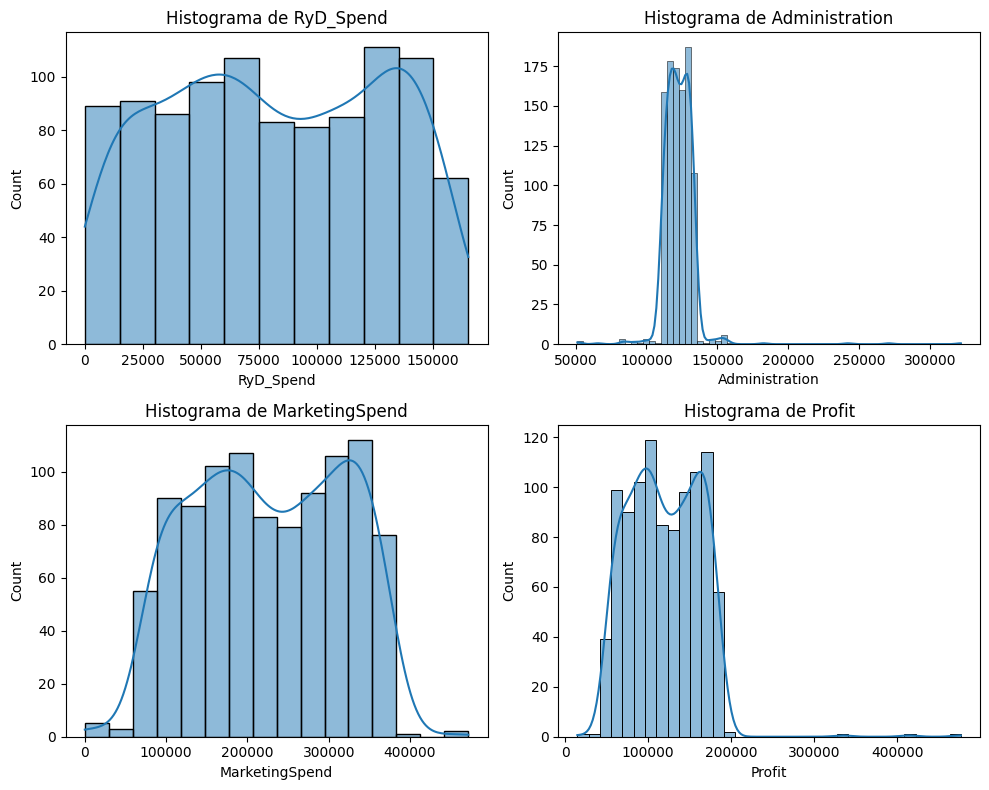

In [5]:
#verificacion de lo analizado anteriormente
cols_num = empresas.select_dtypes(include=['float'])

plt.figure(figsize=(10,8))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.histplot(empresas[col], kde=True)
    plt.title(f"Histograma de {col}")

plt.tight_layout()
plt.show()

Se confirman las sospechas de colas extensas en Profit y en Administration, sobre todo a la derecha, cosa que ambas comparten, si bien Administration posee a ambos lados.

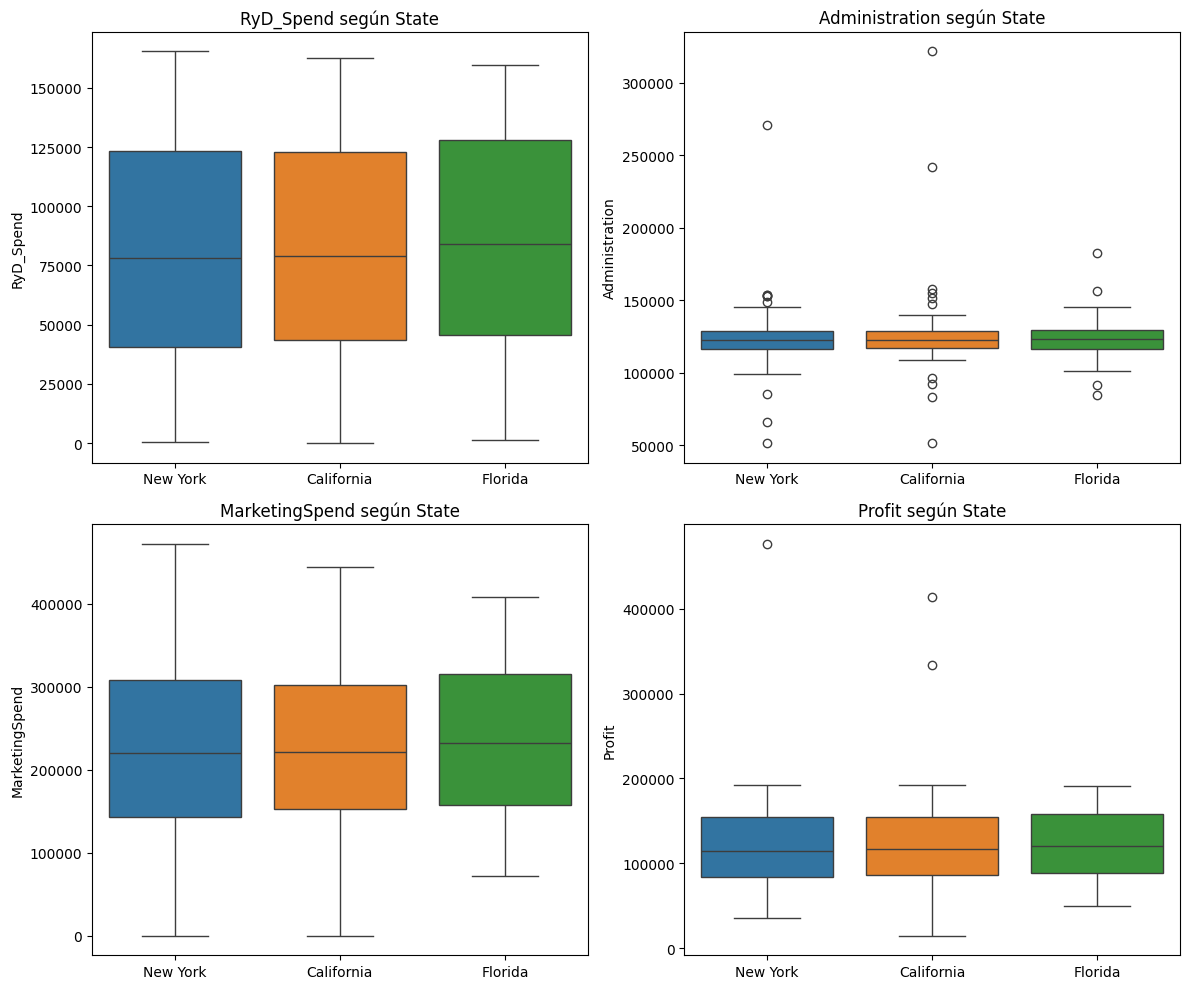

In [6]:
plt.figure(figsize=(12, 10))

for i, col in enumerate(cols_num):
    plt.subplot(2, 2, i+1)
    sns.boxplot(data=empresas, x='State', y=col, hue='State')
    plt.title(f'{col} según State')
    plt.xlabel('')

plt.tight_layout()
plt.show()

Se analizó la distribución de cada variable numérica según State. En los cuatro casos, las medianas y los rangos intercuartiles de New York, California y Florida son muy similares, y los los valores atípicos no se concentran en un único estado. Esto indica que la ubicación de la empresa no se asocia con diferencias en los gastos ni en el Profit, por lo que se decidió no incluir State como variable predictora.

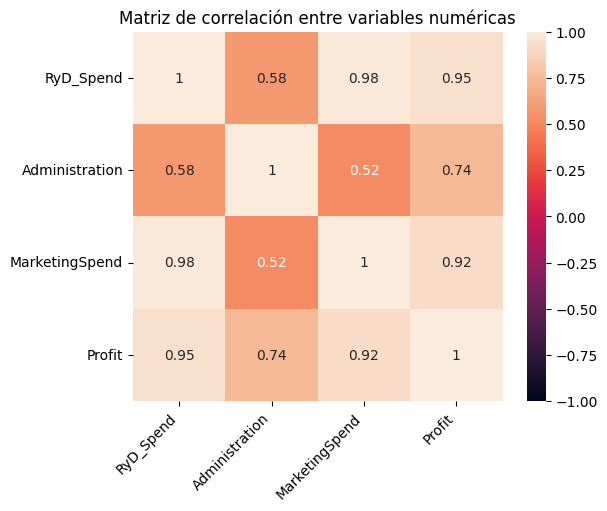

In [7]:
corr = empresas.drop(columns=["State"]).corr()

ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación entre variables numéricas')
plt.show()

Profit presenta una correlación muy alta con RyD_Spend (0.95) y MarketingSpend (0.92), y moderada con Administration (0.74), por lo que se espera que RyD_Spend sea la variable más relevante en los cortes del árbol. Además, RyD_Spend y MarketingSpend están muy correlacionadas entre sí (0.98), lo que indica multicolinealidad para un modelo lineal, pero no para un árbol de decisión.

#### **División Conjuntos Train y Test:**

Se realizan la divisiones de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [8]:
X = empresas[['RyD_Spend', 'Administration', 'MarketingSpend']]
y = empresas['Profit']
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(X, y, test_size=0.2, random_state=63)

print(f"Datos de entrenamiento: {X_train_80.shape} y de test: {X_test_20.shape}")

Datos de entrenamiento: (800, 3) y de test: (200, 3)


In [9]:
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(X, y, test_size=0.3, random_state=63)

print(f"Datos de entrenamiento: {X_train_70.shape} y de test: {X_test_30.shape}")

Datos de entrenamiento: (700, 3) y de test: (300, 3)


#### Observación y tratamiento de outliers

No se estandarizaron las variables predictoras, ya que los árboles de decisión dividen cada variable por umbrales y no se ven afectados por la escala. Sin embargo, en el análisis exploratorio se observaron valores atípicos en la variable objetivo Profit. Dado que el árbol de regresión predice el promedio de cada hoja, estos valores pueden distorsionar sus predicciones. Por ello, se identifican mediante el criterio Q3 + 1,5·IQR, calculado sobre cada conjunto de entrenamiento.

In [10]:
Q1, Q3 = y_train_80.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_80_20 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 80-20: {lim_sup_80_20:.2f}')

X_train_80[y_train_80 > lim_sup_80_20].assign(Profit=y_train_80[y_train_80 > lim_sup_80_20])

Límite superior, div. 80-20: 257787.11


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


In [11]:
Q1, Q3 = y_train_70.quantile([0.25, 0.75])
IQR = Q3 - Q1
lim_sup_70_30 = Q3 + 1.5 * IQR
print(f'Límite superior, div. 70-30: {lim_sup_70_30:.2f}')

X_train_70[y_train_70 > lim_sup_70_30].assign(Profit=y_train_70[y_train_70 > lim_sup_70_30])

Límite superior, div. 70-30: 259600.02


,RyD_Spend,Administration,MarketingSpend,Profit
998,128456.23,321652.14,281692.32,333962.19
997,100275.47,241926.31,227142.82,413956.48


En ambas particiones se identificaron las mismas dos empresas. Para evaluar si estos valores son coherentes con el resto de los datos, se compara su Profit con el Profit mediano de empresas con un nivel de inversión en RyD_Spend similar.

In [12]:
for idx in [997, 998]:
    ryd = X_train_80.loc[idx, 'RyD_Spend']
    similares = y_train_80[(X_train_80['RyD_Spend'] - ryd).abs() < 10000]
    print(f"Empresa {idx}: RyD = {ryd:.0f} | Profit = {y_train_80[idx]:.0f} | "
          f"Profit mediano de empresas similares = {similares.median():.0f}")

Empresa 997: RyD = 100275 | Profit = 413956 | Profit mediano de empresas similares = 136633
Empresa 998: RyD = 128456 | Profit = 333962 | Profit mediano de empresas similares = 159613


Empresa 997: Profit de 413.956, frente a un Profit mediano de 136.633 en empresas similares (aprox. 3 veces mayor).
Empresa 998: Profit de 333.962, frente a un Profit mediano de 159.613 en empresas similares (aprox. 2 veces mayor).

Estos valores no se explican por la inversión de las empresas y, además, ambas presentan valores extremos en Administration, lo que sugiere observaciones anómalas o errores de carga. Dada esta situación, se eliminan del conjunto de entrenamiento esas dos observaciones (menos del 0,3% del conjunto de entrenamiento). El conjunto de test no se modifica.

In [13]:
X_train_80 = X_train_80[y_train_80 <= lim_sup_80_20]
y_train_80 = y_train_80[y_train_80 <= lim_sup_80_20]

X_train_70 = X_train_70[y_train_70 <= lim_sup_70_30]
y_train_70 = y_train_70[y_train_70 <= lim_sup_70_30]

print(f"80/20 → train: {X_train_80.shape}, {y_train_80.shape}")
print(f"70/30 → train: {X_train_70.shape}, {y_train_70.shape}")

80/20 → train: (798, 3), (798,)
70/30 → train: (698, 3), (698,)


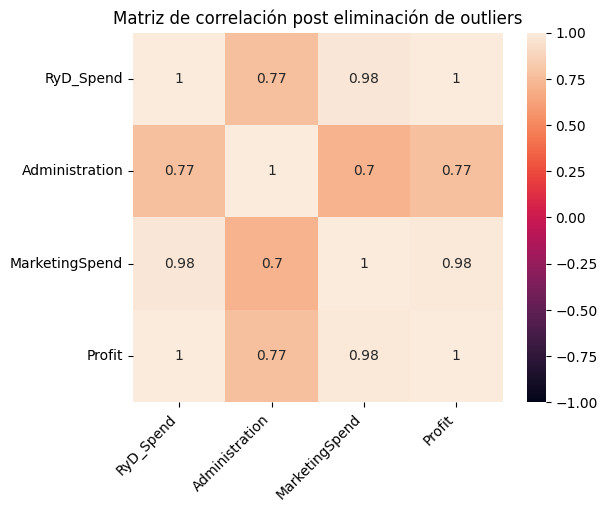

In [14]:
corr = X_train_80.assign(Profit=y_train_80).corr()
ax = sns.heatmap(corr,vmin=-1, vmax=1, square=True, annot=True)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
plt.title('Matriz de correlación post eliminación de outliers')
plt.show()

Al comparar la matriz de correlación del dataset completo con la del conjunto de entrenamiento 80/20 sin los outliers removidos, se observa que todas las correlaciones aumentaron o se mantuvieron. Las relaciones de Profit con RyD_Spend (de 0.95 a prácticamente 1) y con MarketingSpend (de 0.92 a 0.98) se fortalecen, y los cambios más marcados se dan en Administration, cuya correlación con RyD_Spend y MarketingSpend sube cerca de 0.2 puntos. Esto confirma que las observaciones eliminadas no seguían el patrón general de los datos y debilitaban las relaciones entre variables.

### **Punto 2 - Árboles de decisión para regresión**

#### **Conjunto 80/20:**

a) Variando la profundidad del árbol (**max_deph**):

In [15]:
profundidades = [2, 6, 10, 14]

resultados = []

for prof in profundidades:

    tree_reg = DecisionTreeRegressor(max_depth=prof,criterion='squared_error',min_samples_leaf=1,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'max_depth': prof,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,max_depth,MAE,MSE,RMSE
0,2,10485.95,5.812224e+08,24108.55
1,6,2692.92,4.328169e+08,20804.25
2,10,2166.03,4.401294e+08,20979.26
3,14,2105.84,4.301543e+08,20740.16


Observaciones:

A profundidades bajas (max_depth=2) se evidencia subajuste (underfitting), con un MAE superior a 10.000. Al incrementar la profundidad hasta 14, el MAE disminuye de forma constante, alcanzando su mínimo (2.105,84). El RMSE, en cambio, se mantiene prácticamente estable entre 6 y 14, ya que está dominado por una única observación del conjunto de test (Profit ≈ 476.000) con un error muy grande; por eso la selección se basa en el MAE.

b) Variando el número mínimo de observaciones por hoja (**min_samples_leaf**) :

In [16]:
observaciones = [1, 3, 5]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=obs,min_samples_split=2,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_leaf': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_leaf,MAE,MSE,RMSE
0,1,2105.84,4.301543e+08,20740.16
1,3,2337.60,4.420906e+08,21025.95
2,5,2428.37,4.331454e+08,20812.15


Observaciones:

Permitir hojas unitarias (min_samples_leaf=1) logra la mayor precisión puntual en las estimaciones. Restringir el tamaño mínimo de hoja a 3 o 5 incrementa el MAE y el RMSE, por lo que se conserva el valor 1 para capturar la alta correlación lineal que presenta la variable objetivo.

c) Variando el número mínimo de observaciones para realizar una separación (**min_samples_split**):

In [17]:
observaciones = [2, 5, 10, 15, 20]

resultados = []

for obs in observaciones:

    tree_reg = DecisionTreeRegressor(max_depth=14,criterion='squared_error',min_samples_leaf=1,min_samples_split=obs,random_state=63)

    # Entrenamiento
    tree_reg.fit(X_train_80, y_train_80)

    # Predicciones
    y_pred = tree_reg.predict(X_test_20)

    # Métricas
    mae = round(mean_absolute_error(y_test_20, y_pred), 2)
    mse = round(mean_squared_error(y_test_20, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados.append({'min_samples_split': obs,'MAE': mae,'MSE': mse,'RMSE': rmse})

resultados_empresas1 = pd.DataFrame(resultados)
display(resultados_empresas1)

,min_samples_split,MAE,MSE,RMSE
0,2,2105.84,4.301543e+08,20740.16
1,5,2217.57,4.312123e+08,20765.65
2,10,2392.22,4.602612e+08,21453.70
3,15,2641.15,4.601767e+08,21451.73
4,20,2610.65,4.334907e+08,20820.44


Observaciones:

El menor error se obtiene con min_samples_split=2. Valores mayores (como 10, 15 o 20) frenan prematuramente las particiones en rangos donde aún existía margen de ganancia en la reducción del error cuadrático

d) Visualización del árbol seleccionado:

In [18]:
tree_reg1 = DecisionTreeRegressor(max_depth=14, min_samples_leaf=1, min_samples_split=2,
                                  criterion='squared_error', random_state=63)
# Entrenamiento
tree_reg1.fit(X_train_80, y_train_80)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",63
,"max_lea

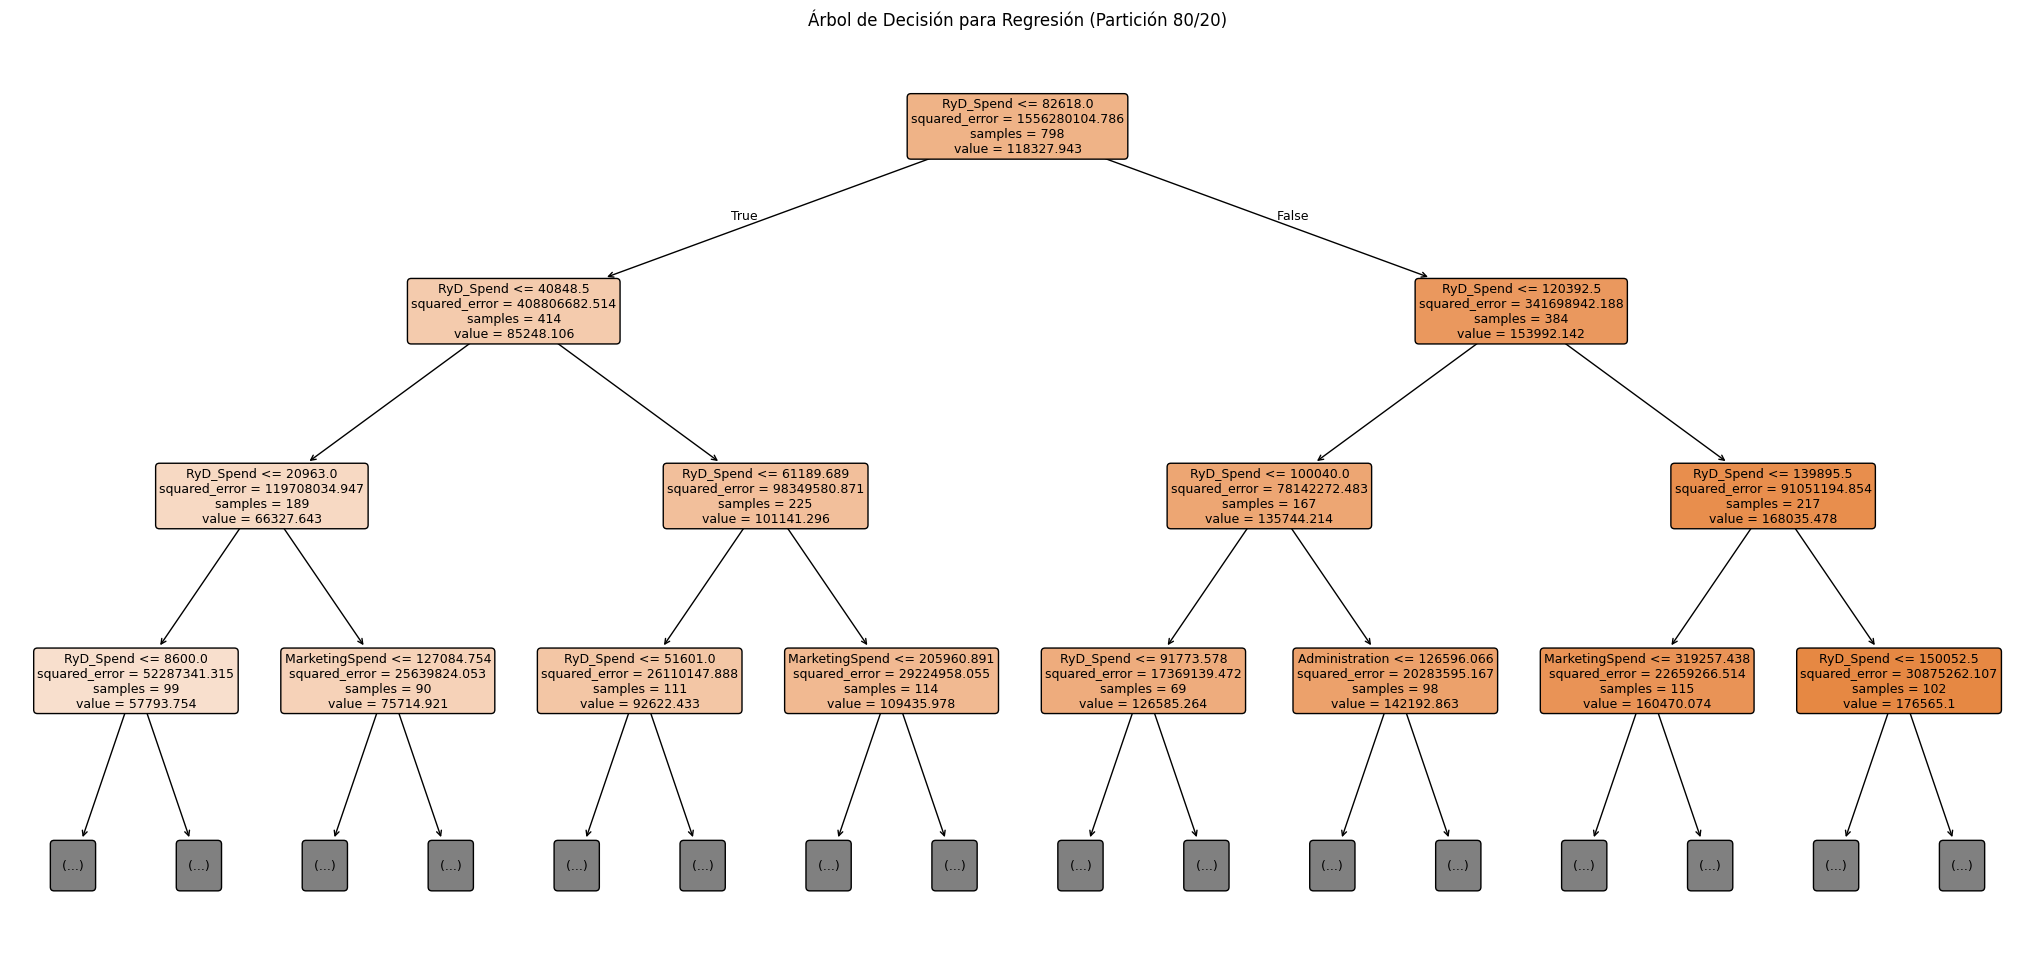

In [19]:
# Gráfico del árbol obtenido
plt.figure(figsize=(26, 12))
plot_tree(
    tree_reg1,
    feature_names=X_train_80.columns,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3  # Mostramos hasta el nivel 3 para que sea legible
)
plt.title("Árbol de Decisión para Regresión (Partición 80/20)")
plt.show()

Se grafican los primeros tres niveles del árbol seleccionado (max_depth = 14, min_samples_leaf = 1, min_samples_split = 2) para facilitar su lectura. Las primeras divisiones se realizan sobre RyD_Spend, lo que confirma que es la variable más relevante, en línea con su correlación casi perfecta con Profit. Las predicciones de las hojas aumentan progresivamente con RyD_Spend, lo que muestra cómo el árbol aproxima esa relación lineal mediante escalones. MarketingSpend y Administration recién aparecen en el cuarto nivel, como ajustes finos dentro de grupos ya separados por RyD_Spend.

#### **Conjunto 70/30:**

In [20]:
# Asignamos directamente las variables de la partición 70/30 ya definidas y procesadas anteriormente
X2_train = X_train_70
y2_train = y_train_70

X2_test = X_test_30
y2_test = y_test_30

a) Variando la profundidad del árbol ('max_deph'):

In [21]:

profundidades = [2, 4, 6, 8, 10, 14]
resultados_depth_70 = []

for prof in profundidades:
    tree_reg = DecisionTreeRegressor(
        max_depth=prof,
        criterion='squared_error',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_reg.fit(X_train_70, y_train_70)
    y_pred = tree_reg.predict(X_test_30)

    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_depth_70.append({'max_depth': prof, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_depth_70))

,max_depth,MAE,MSE,RMSE
0,2,9684.89,4.166035e+08,20410.87
1,4,3648.37,3.003179e+08,17329.68
2,6,2113.37,2.897558e+08,17022.22
3,8,1740.18,2.890326e+08,17000.96
4,10,1599.92,3.022256e+08,17384.64
5,14,1569.89,2.948581e+08,17171.43


Se determinó que el valor óptimo es max_depth = 14, ya que presenta el menor MAE (1.569,89). El MAE disminuye de forma sostenida al aumentar la profundidad, con mejoras cada vez menores a partir de 8. Al igual que en el 80/20, el RMSE se mantiene estable porque está dominado por una única observación del test con un error muy grande, por lo que la selección se basa en el MAE.

b) Variando el mínimo de observaciones por hoja (min_samples_leaf) con el mejor max_depth

In [22]:
# b) Variando el mínimo de observaciones por hoja (min_samples_leaf) con el mejor max_depth
observaciones_leaf = [1, 2, 3, 5, 7, 10]
resultados_leaf_70 = []

for obs in observaciones_leaf:
    tree_reg = DecisionTreeRegressor(
        max_depth=14,
        criterion='squared_error',
        min_samples_leaf=obs,
        min_samples_split=2,
        random_state=63
    )
    # entrenamiento
    tree_reg.fit(X_train_70, y_train_70)
    # predicciones
    y_pred = tree_reg.predict(X_test_30)
    # metricas
    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_leaf_70.append({'min_samples_leaf': obs, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_leaf_70))

,min_samples_leaf,MAE,MSE,RMSE
0,1,1569.89,2.948581e+08,17171.43
1,2,1625.23,3.046493e+08,17454.21
2,3,1771.04,3.081454e+08,17554.07
3,5,1857.65,2.897577e+08,17022.27
4,7,1974.16,2.900622e+08,17031.21
5,10,2168.41,3.087564e+08,17571.47


Fijando max_depth = 14, se selecciona min_samples_leaf = 1, ya que presenta el menor MAE. Al aumentar el tamaño mínimo de hoja, el MAE crece de forma sostenida, porque el árbol pierde capacidad para aproximar con precisión la relación entre RyD_Spend y Profit.

c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [23]:
observaciones_split = [2, 5, 10, 15, 20]
resultados_split_70 = []

for obs in observaciones_split:
    tree_reg = DecisionTreeRegressor(
        max_depth=14,
        criterion='squared_error',
        min_samples_leaf=1,
        min_samples_split=obs,
        random_state=63
    )
    tree_reg.fit(X_train_70, y_train_70)
    y_pred = tree_reg.predict(X_test_30)

    mae = round(mean_absolute_error(y_test_30, y_pred), 2)
    mse = round(mean_squared_error(y_test_30, y_pred), 2)
    rmse = round(np.sqrt(mse), 2)

    resultados_split_70.append({'min_samples_split': obs, 'MAE': mae, 'MSE': mse, 'RMSE': rmse})

display(pd.DataFrame(resultados_split_70))

,min_samples_split,MAE,MSE,RMSE
0,2,1569.89,2.948581e+08,17171.43
1,5,1610.59,3.116261e+08,17652.93
2,10,1844.59,3.100605e+08,17608.54
3,15,1997.23,3.058171e+08,17487.63
4,20,2136.54,2.904715e+08,17043.22


Fijando max_depth = 14 y min_samples_leaf = 1, se selecciona min_samples_split = 2, ya que presenta el menor MAE (1.569,89). Valores mayores impiden dividir nodos con pocas observaciones, lo que vuelve más gruesa la aproximación y aumenta el error.

d) Visualización del árbol seleccionado

In [24]:
# d) Entrenamiento del modelo final 70/30
tree_reg2 = DecisionTreeRegressor(
    max_depth=14,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='squared_error',
    random_state=63
)
tree_reg2.fit(X_train_70, y_train_70)


,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",14
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",63
,"max_lea

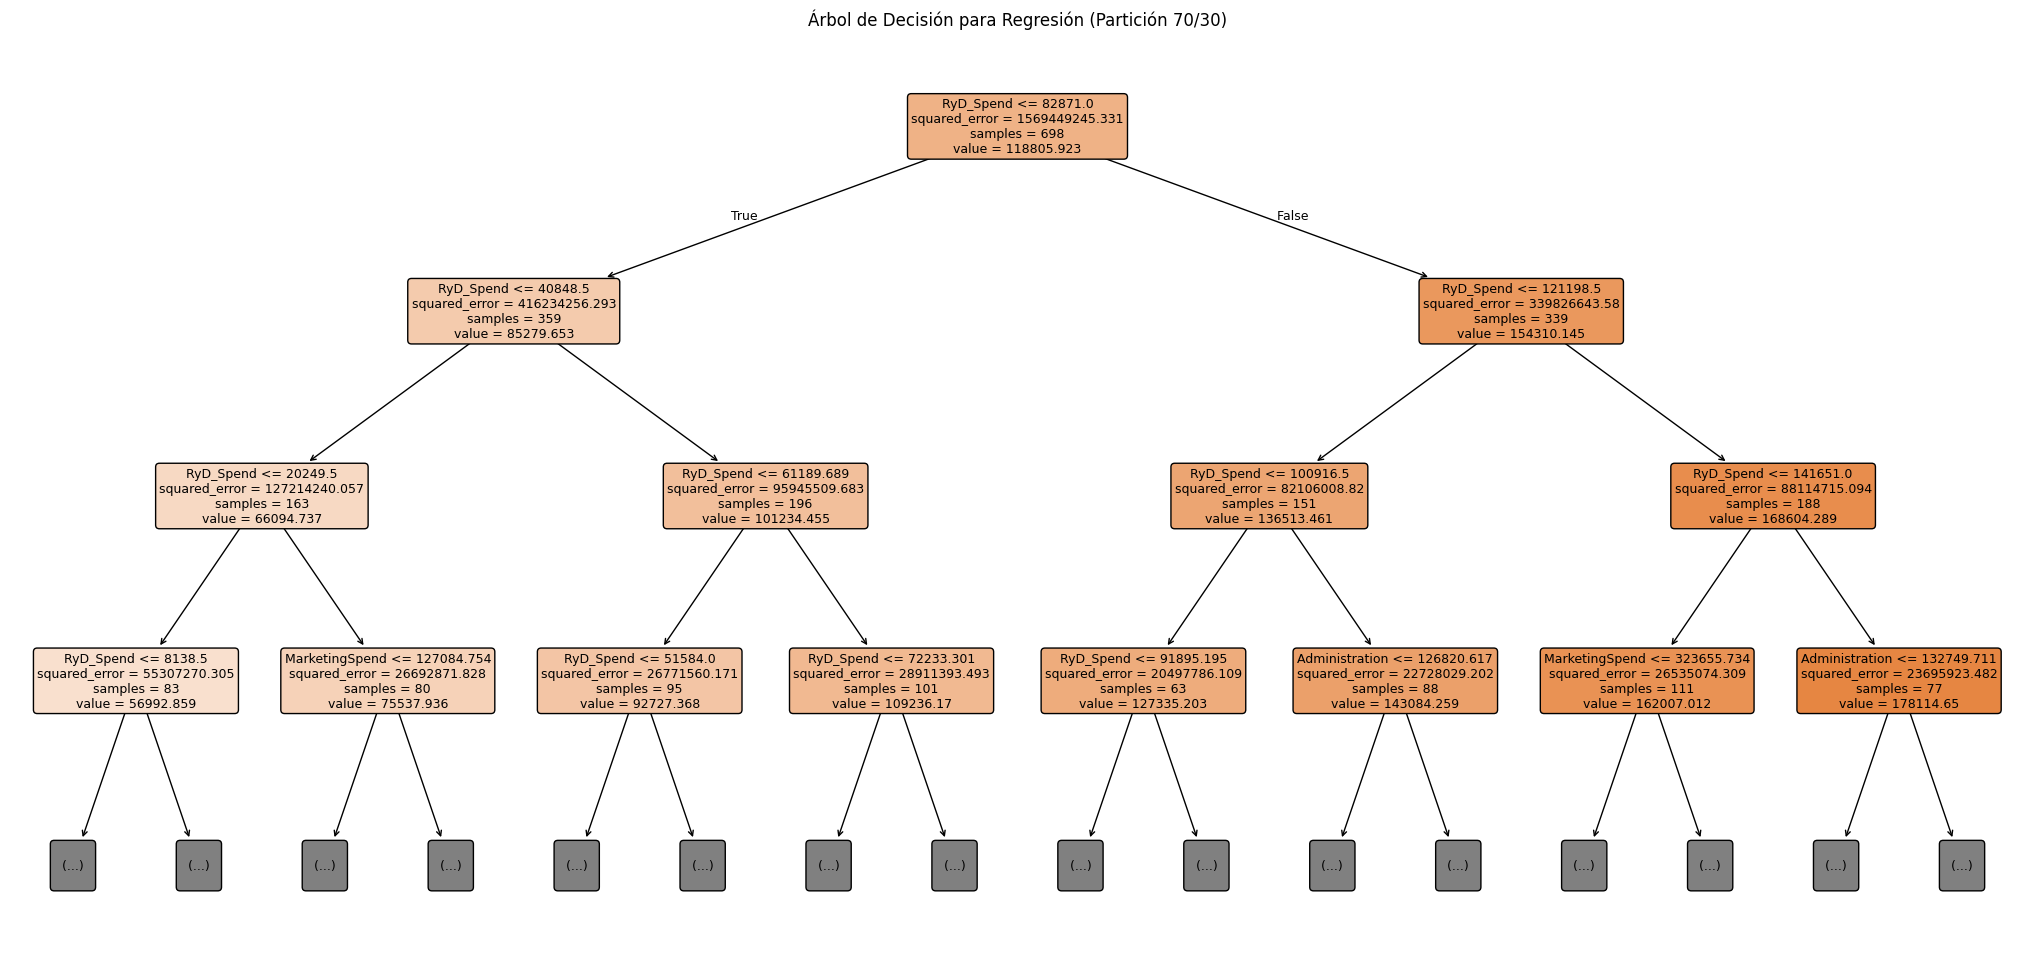

In [25]:
# Gráfico del árbol obtenido
plt.figure(figsize=(26, 12))
plot_tree(
    tree_reg2,
    feature_names=X_train_70.columns,
    filled=True,
    rounded=True,
    fontsize=9,
    max_depth=3  # Mostramos hasta el nivel 3 para que sea legible
)
plt.title("Árbol de Decisión para Regresión (Partición 70/30)")
plt.show()

Se grafican los primeros tres niveles del árbol seleccionado (max_depth = 14, min_samples_leaf = 1, min_samples_split = 2). Su estructura es prácticamente idéntica a la del árbol 80/20: los tres primeros niveles dividen exclusivamente por RyD_Spend, con umbrales casi iguales (por ejemplo, 82.871 frente a 82.618 en la raíz), y MarketingSpend y Administration aparecen recién en el cuarto nivel. Esto indica que el modelo aprende la misma relación independientemente de la partición, lo que refuerza su estabilidad.

### **Conclusiones:**

In [26]:
# Tabla comparativa de métricas sobre ambos conjuntos de test
resultados_finales = []

# 1. Evaluación Modelo Óptimo 80/20 sobre test_20
pred_80 = tree_reg1.predict(X_test_20)
mae_80 = mean_absolute_error(y_test_20, pred_80)
mse_80 = mean_squared_error(y_test_20, pred_80)
rmse_80 = np.sqrt(mse_80)

resultados_finales.append({
    'Modelo': '80/20 (depth=14, leaf=1, split=2)',
    'MAE': round(mae_80, 2),
    'MSE': round(mse_80, 2),
    'RMSE': round(rmse_80, 2)
})

# 2. Evaluación Modelo Óptimo 70/30 sobre test_30
pred_70 = tree_reg2.predict(X_test_30)
mae_70 = mean_absolute_error(y_test_30, pred_70)
mse_70 = mean_squared_error(y_test_30, pred_70)
rmse_70 = np.sqrt(mse_70)

resultados_finales.append({
    'Modelo': '70/30 (depth=14, leaf=1, split=2)',
    'MAE': round(mae_70, 2),
    'MSE': round(mse_70, 2),
    'RMSE': round(rmse_70, 2)
})

tabla_comparacion = pd.DataFrame(resultados_finales)
display(tabla_comparacion)

,Modelo,MAE,MSE,RMSE
0,"80/20 (depth=14, leaf=1, split=2)",2105.84,4.301543e+08,20740.16
1,"70/30 (depth=14, leaf=1, split=2)",1569.89,2.948581e+08,17171.43


Ambos modelos alcanzan un error bajo en relación con la escala de la variable objetivo: un MAE de 2.105,84 en el 80/20 y de 1.569,89 en el 70/30, lo que representa menos del 2% del Profit medio (≈119.500). La diferencia entre ambos se explica principalmente por la composición de cada conjunto de test, ya que los dos árboles aprendieron una estructura prácticamente idéntica.

El RMSE resulta muy superior al MAE en ambos casos (≈20.700 y ≈17.200) porque está dominado por una única observación presente en los dos conjuntos de test (Profit ≈ 476.000), cuyo error de aproximadamente 286.000 concentra casi todo el MSE. Por eso, el MAE es la métrica más representativa del desempeño del modelo sobre la mayoría de las observaciones.

En ambos árboles las primeras divisiones se realizan sobre RyD_Spend, en línea con su correlación casi perfecta con Profit (0,95 en el dataset completo y prácticamente 1 tras eliminar las observaciones anómalas).

---

# PARTE B - Clasificación (dataset drugType.csv)

### Funciones auxiliares

In [27]:

def target_balance(df, target_col):
    """Muestra la tabla de frecuencias absoluta y relativa de las clases."""
    cantidad = df[target_col].value_counts()
    porcentaje = df[target_col].value_counts(normalize=True) * 100
    tabla = pd.DataFrame({
        'Cantidad': cantidad,
        'Porcentaje': porcentaje.map('{:.1f}%'.format)
    })
    print(f"Distribución de clases para '{target_col}':")
    display(tabla)

def outliers_iqr(datos, var: str):
    """Detecta y remueve outliers según el rango intercuartil (IQR)."""
    Q1 = datos[var].quantile(0.25)
    Q3 = datos[var].quantile(0.75)
    IQR = Q3 - Q1
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    cant_inic = len(datos)
    datos_limpios = datos[(datos[var] >= lim_inf) & (datos[var] <= lim_sup)]
    print(f"En '{var}': se eliminaron {cant_inic - len(datos_limpios)} filas (Límites: [{lim_inf:.2f}, {lim_sup:.2f}]).")
    return datos_limpios


def discretizar(datos_train, datos_test, columnas, n_bins):
    """
    Discretiza por frecuencia igual (cuantiles) usando los límites del Train para el Test.
    """
    datos_train = datos_train.copy()
    datos_test = datos_test.copy()

    for col in columnas:
        # 1. Calculamos los límites de los cuantiles únicamente sobre el TRAIN
        _, bins = pd.qcut(
            datos_train[col],
            q=n_bins,
            retbins=True,
            labels=False,
            duplicates='drop'
        )
        # 2. Extendemos los extremos a infinito para evitar NaN si en TEST hay valores fuera del rango
        bins[0] = -np.inf
        bins[-1] = np.inf
        # 3. Aplicamos los mismos cortes en TRAIN
        datos_train[f'{col}_disc'] = pd.cut(
            datos_train[col],
            bins=bins,
            labels=False,
            include_lowest=True
        )
        # 4. Aplicamos esos mismos límites sobre el TEST (evita data leakage)
        datos_test[f'{col}_disc'] = pd.cut(
            datos_test[col],
            bins=bins,
            labels=False,
            include_lowest=True
        )

    return datos_train, datos_test

### **Punto 3 - Preparación de datos y Análisis Exploratorio (EDA)**

In [28]:
# CARGA Y REVISIÓN INICIAL
farmac = pd.read_csv('drugType.csv')
farmac.info()


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 12.7 KB


Se puede observar que el conjunto de datos no presenta datos faltantes.

In [29]:
farmac.head()


,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


In [30]:
# Verificamos el desbalance de clases de la variable objetivo
target_balance(farmac, 'Droga')

Distribución de clases para 'Droga':


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5%
DrogaX,54,27.0%
DrogaA,23,11.5%
DrogaC,16,8.0%
DrogaB,16,8.0%


In [31]:
farmac.describe()

,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Análisis de Variables:

***Edad :***

**Media:** 44.31 | **Mediana:** 45  
Presenta una Media y una Mediana muy similar, lo que se puede asociar a una distribución aparentemente simetrica sin presencia de valores extremos.

**Rango:** 15 – 74  

**Desviación estándar:** 16.54


---
***Na_a_K:***

**Media:** 16.08 | **Mediana:** 13.93  
La Media y la Mediana son iguales, por lo que sugiere una distribucion simetrica.

**Rango:** 6.26 – 38.24

**Desviación estándar:**  7.22

In [32]:
# Lista columnas categóricas
col_cat = ['Sexo','BP','Colesterol','Droga']

for col in col_cat:
    print(f"Valores únicos en {col}: {farmac[col].unique()}")

Valores únicos en Sexo: <ArrowStringArray>
['F', 'M']
Length: 2, dtype: str
Valores únicos en BP: <ArrowStringArray>
['Alto', 'Bajo', 'Normal']
Length: 3, dtype: str
Valores únicos en Colesterol: <ArrowStringArray>
['Alto', 'Normal']
Length: 2, dtype: str
Valores únicos en Droga: <ArrowStringArray>
['DrogaY', 'DrogaC', 'DrogaX', 'DrogaA', 'DrogaB']
Length: 5, dtype: str


***Sexo :***

**Valores:** F -M

---
***BP:***

**Valores:** Bajo - Normal - Alto

---
***Colesterol:***

**Valores:** Normal - Alto  

---
***Drogra:***

**Valores:** DrogaA - DrogaB - DrogaC- DrogaX - DrogaY



In [33]:
# CODIFICACIÓN DE CATEGÓRICAS

# Mapeo con orden lógico / ordinal para variables clínicas y binarias
farmac['Sexo_cod'] = farmac['Sexo'].map({'F': 1, 'M': 0})
farmac['BP_cod'] = farmac['BP'].map({'Bajo': 0, 'Normal': 1, 'Alto': 2})
farmac['Colesterol_cod'] = farmac['Colesterol'].map({'Normal': 0, 'Alto': 1})

# Codificación de la variable objetivo (Droga) de 0 a 4
map_droga = {'DrogaA': 0, 'DrogaB': 1, 'DrogaC': 2, 'DrogaX': 3, 'DrogaY': 4}
farmac['Droga_cod'] = farmac['Droga'].map(map_droga)

display(farmac[['Sexo', 'Sexo_cod', 'BP', 'BP_cod', 'Colesterol', 'Colesterol_cod', 'Droga', 'Droga_cod']].head())

,Sexo,Sexo_cod,BP,BP_cod,Colesterol,Colesterol_cod,Droga,Droga_cod
0,F,1,Alto,2,Alto,1,DrogaY,4
1,M,0,Bajo,0,Alto,1,DrogaC,2
2,M,0,Bajo,0,Alto,1,DrogaC,2
3,F,1,Normal,1,Alto,1,DrogaX,3
4,F,1,Bajo,0,Alto,1,DrogaY,4


 División Conjuntos Train y Test:

 Realizamos la división de los conjuntos de Train y Test. Uno con la proporción 80/20 y otro con la proporción 70/30.

In [34]:

# Partición 80/20 con estratificación obligatoria
farmac1_train, farmac1_test = train_test_split(
    farmac,
    test_size=0.2,
    random_state=63,
    stratify=farmac['Droga_cod']
)
farmac1_train = farmac1_train.copy(deep=True)
farmac1_test = farmac1_test.copy(deep=True)


In [35]:

# Partición 70/30 con estratificación obligatoria
farmac2_train, farmac2_test = train_test_split(
    farmac,
    test_size=0.3,
    random_state=63,
    stratify=farmac['Droga_cod']
)
farmac2_train = farmac2_train.copy(deep=True)
farmac2_test = farmac2_test.copy(deep=True)

In [36]:
print(f"Partición 80/20 -> Train: {farmac1_train.shape}, Test: {farmac1_test.shape}")
print(f"Partición 70/30 -> Train: {farmac2_train.shape}, Test: {farmac2_test.shape}")

Partición 80/20 -> Train: (160, 10), Test: (40, 10)
Partición 70/30 -> Train: (140, 10), Test: (60, 10)


Analisis y tratamiento de los datos utilizados para train :

Conjunto 80/20

Se realizan visualizaciones de los boxplots de las variables Edad y Na_a_K antes y despues de hacer la eliminacion de los outliers en el conjunto de train.



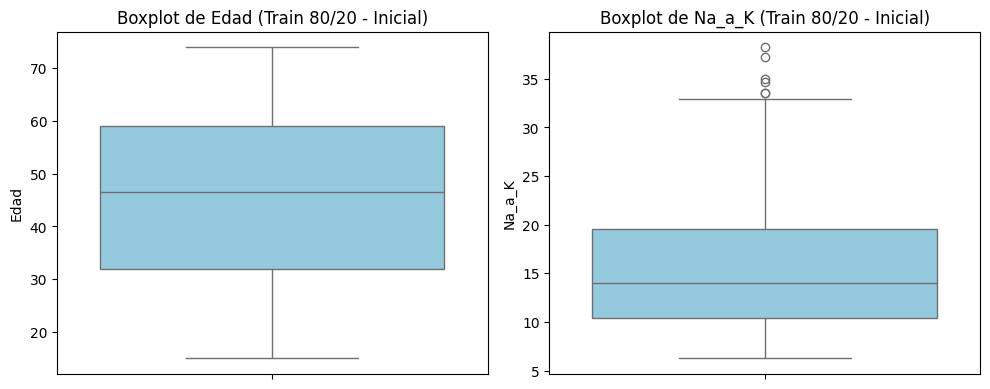

En 'Na_a_K': se eliminaron 6 filas (Límites: [-3.27, 33.26]).


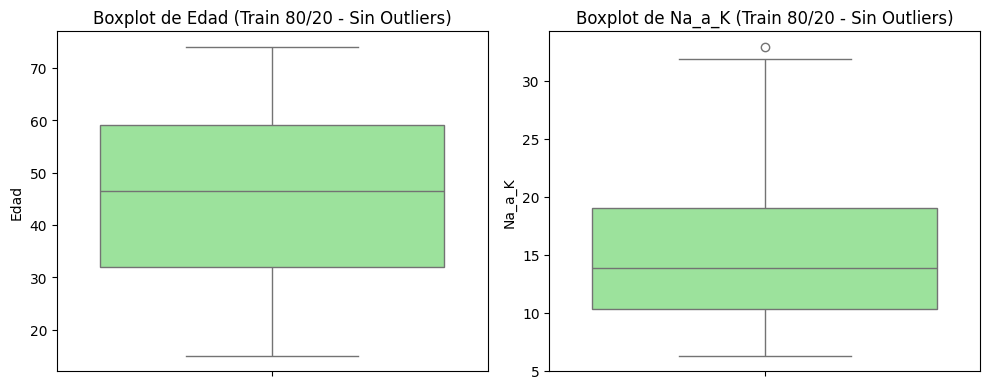

In [37]:
# Visualización de outliers antes del filtrado
cols_num = ['Edad', 'Na_a_K']

plt.figure(figsize=(10, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=farmac1_train[col], color='skyblue')
    plt.title(f"Boxplot de {col} (Train 80/20 - Inicial)")
plt.tight_layout()
plt.show()

# Eliminación de outliers exclusivamente sobre farmac1_train
farmac1_train = outliers_iqr(farmac1_train, 'Na_a_K')

# Boxplot posterior para verificar el efecto
plt.figure(figsize=(10, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=farmac1_train[col], color='lightgreen')
    plt.title(f"Boxplot de {col} (Train 80/20 - Sin Outliers)")
plt.tight_layout()
plt.show()

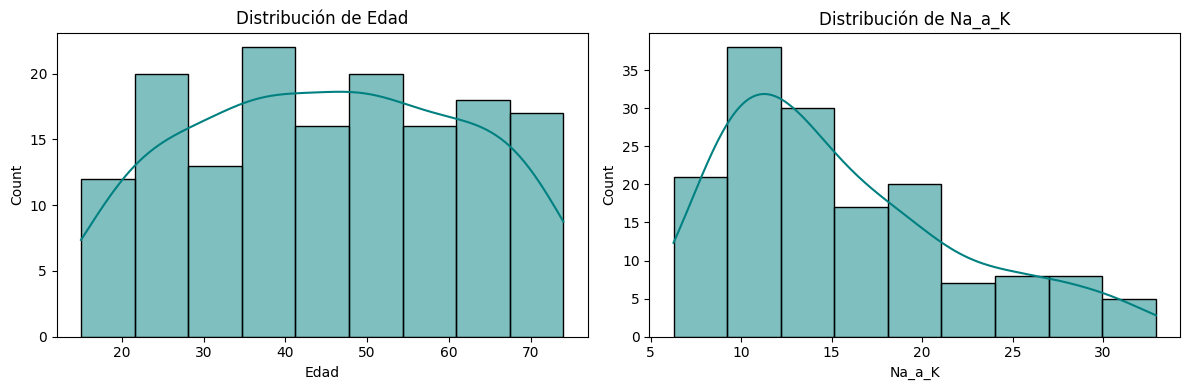

In [38]:
# Histogramas de variables numéricas
plt.figure(figsize=(12, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.histplot(farmac1_train[col], kde=True, color='teal')
    plt.title(f"Distribución de {col}")
plt.tight_layout()
plt.show()


C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2005480828.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac1_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2005480828.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac1_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2005480828.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac1_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\20

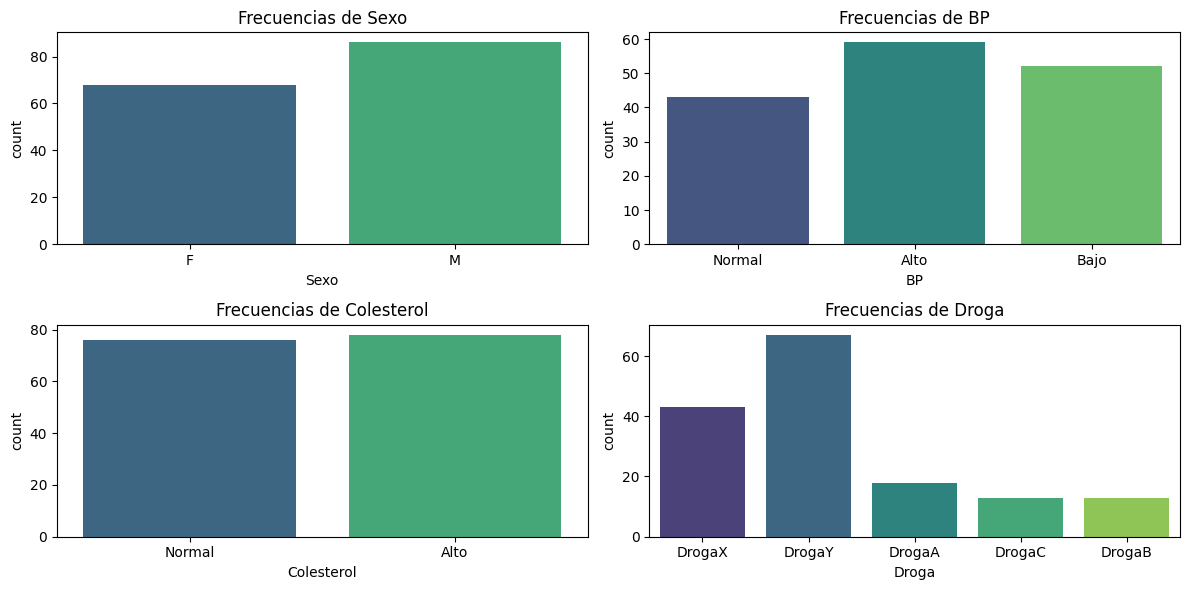

In [39]:
# Frecuencia de variables categóricas
col_cat = ['Sexo', 'BP', 'Colesterol', 'Droga']
plt.figure(figsize=(12, 6))
for i, col in enumerate(col_cat):
    plt.subplot(2, 2, i + 1)
    sns.countplot(data=farmac1_train, x=col, palette='viridis')
    plt.title(f"Frecuencias de {col}")
plt.tight_layout()
plt.show();

Observamos que la variable Droga presenta un marcado desbalance de clases. La DrogaY es la categoría con notablemente mas observaciones, mientras que A, B y C cuentan con muchas menos.

La variable Colesterol muestra una distribución uniforme, mientras que en Sexo y BP se observan ligeras predominancias de las categorías 'Masculino' y 'Alto'.

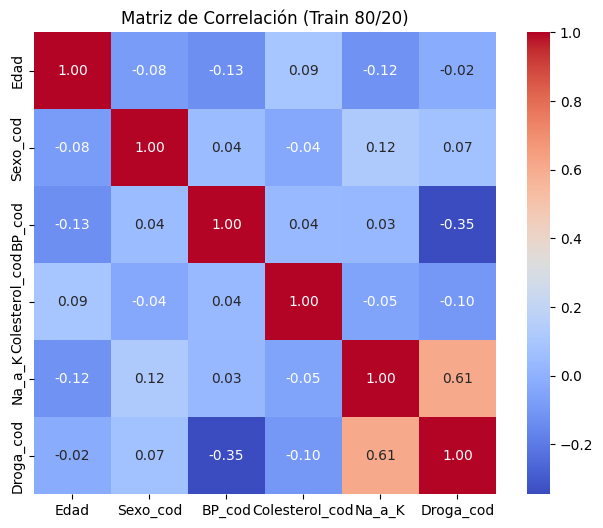

In [40]:

# Matriz de correlación
plt.figure(figsize=(8, 6))
corr_cols = ['Edad', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K', 'Droga_cod']
sns.heatmap(farmac1_train[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title("Matriz de Correlación (Train 80/20)")
plt.show()

Identificamos que la variable Na_a_K presenta la mayor asociación con la variable Droga.

La BP muestra una correlación negativa moderada de -0.35. Variables como la Edad, el Sexo y el Colesterol tienen coeficientes cercanos a cero, lo que sugiere que no existe una relación lineal directa y fuerte entre estos atributos y la droga, dejando la capacidad predictiva principalmente a los factores químicos y de presión del paciente.

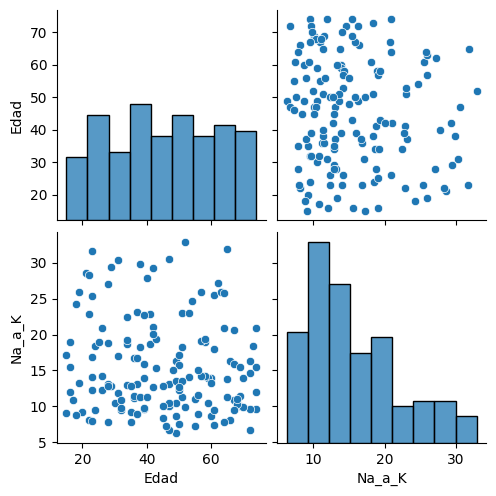

In [41]:
# PAIRPLOT :
sns.pairplot(farmac1_train[['Edad','Na_a_K']])
plt.show()

#### Conjunto 70/30

Se realizaron boxplots para cada variable numérica con el objetivo de identificar la presencia de valores atípicos.

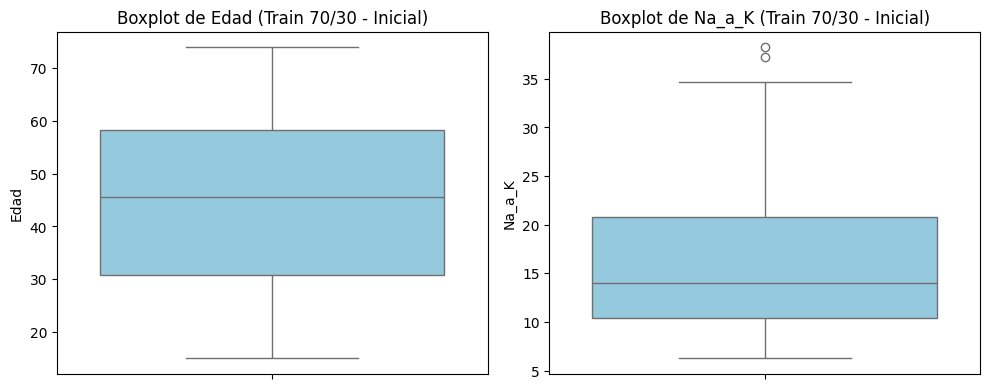

En 'Na_a_K': se eliminaron 2 filas (Límites: [-5.18, 36.30]).


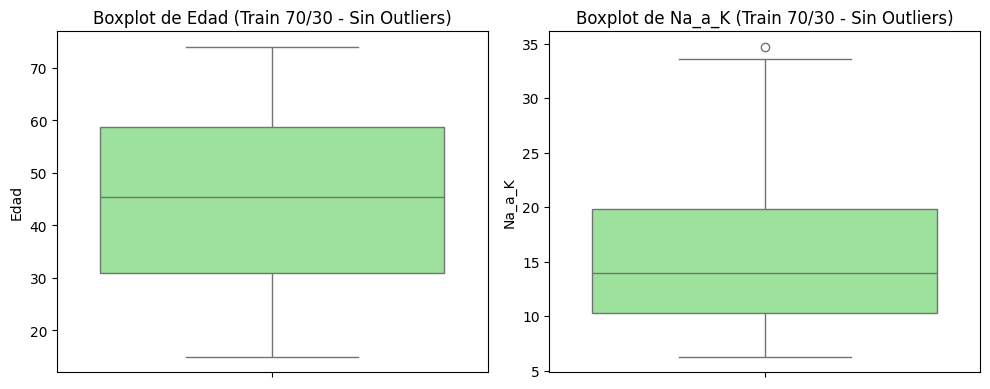

In [42]:
# Boxplot y tratamiento en train 70/30
plt.figure(figsize=(10, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=farmac2_train[col], color='skyblue')
    plt.title(f"Boxplot de {col} (Train 70/30 - Inicial)")
plt.tight_layout()
plt.show()

# Eliminación de outliers exclusivamente sobre farmac2_train
farmac2_train = outliers_iqr(farmac2_train, 'Na_a_K')

# Boxplot posterior
plt.figure(figsize=(10, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=farmac2_train[col], color='lightgreen')
    plt.title(f"Boxplot de {col} (Train 70/30 - Sin Outliers)")
plt.tight_layout()
plt.show()

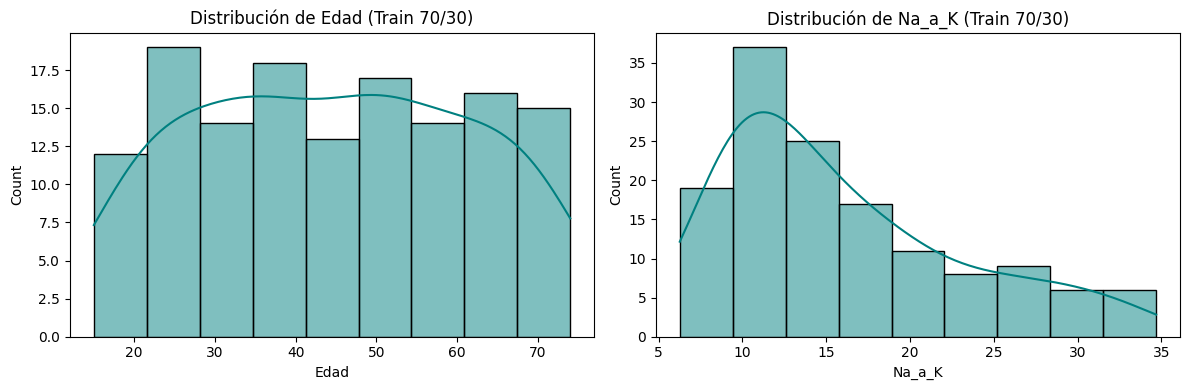

In [43]:
# HISTOGRAMAS 70/30
plt.figure(figsize=(12, 4))
for i, col in enumerate(cols_num):
    plt.subplot(1, 2, i + 1)
    sns.histplot(farmac2_train[col], kde=True, color='teal')
    plt.title(f"Distribución de {col} (Train 70/30)")
plt.tight_layout()
plt.show()

C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2033361825.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac2_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2033361825.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac2_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\2033361825.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=farmac2_train, x=col, palette='viridis')
C:\Users\Carolina\AppData\Local\Temp\ipykernel_21904\20

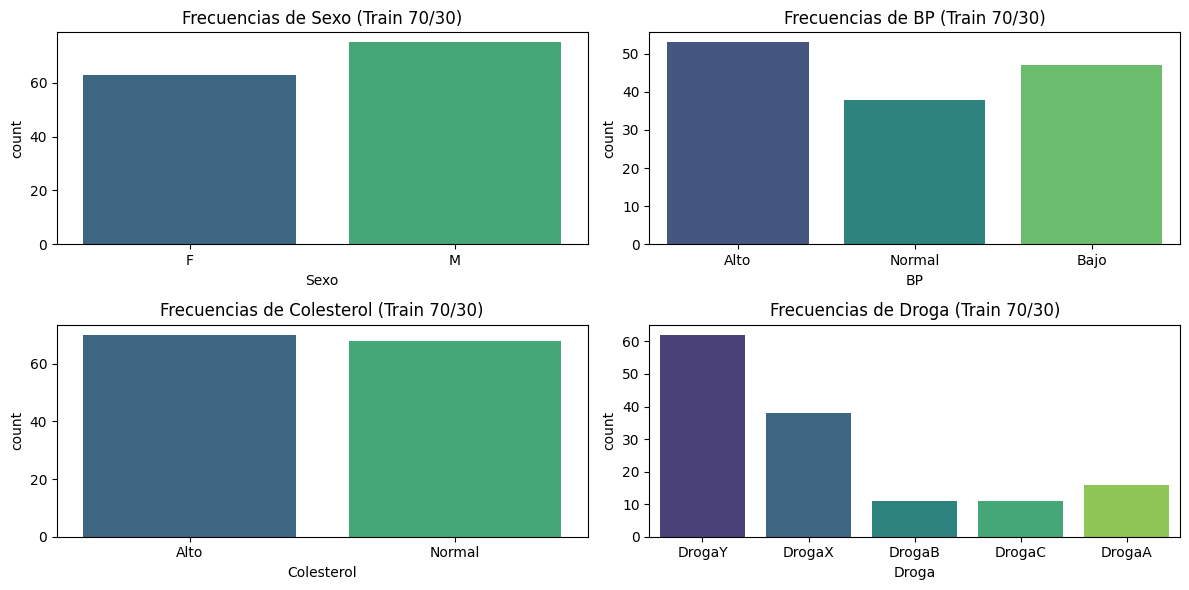

In [44]:
#  COUNTPLOT 70/30
plt.figure(figsize=(12, 6))
for i, col in enumerate(col_cat):
    plt.subplot(2, 2, i + 1)
    sns.countplot(data=farmac2_train, x=col, palette='viridis')
    plt.title(f"Frecuencias de {col} (Train 70/30)")
plt.tight_layout()
plt.show()

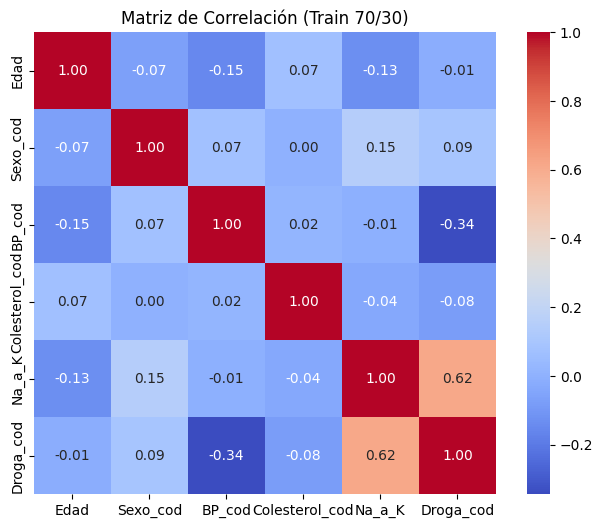

In [45]:
# MATRIZ DE CORRELACION 70/30
plt.figure(figsize=(8, 6))
corr_cols = ['Edad', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K', 'Droga_cod']
sns.heatmap(
    farmac2_train[corr_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    square=True
)
plt.title("Matriz de Correlación (Train 70/30)")
plt.show()


Las proporciones de las clases (Droga) y de las variables categóricas se mantienen prácticamente idénticas al 80/20 gracias a haber aplicado la estratificación en el split.

La correlación lineal más relevante sigue siendo la de Na_a_K con la variable objetivo Droga_cod.

Separación final de matrices X e y para modelado

In [46]:

# Variables predictoras y objetivo
features = ['Edad', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K']
target = 'Droga_cod'

# Partición 80/20
X1_train = farmac1_train[features]
y1_train = farmac1_train[target]
X1_test = farmac1_test[features]
y1_test = farmac1_test[target]

# Partición 70/30
X2_train = farmac2_train[features]
y2_train = farmac2_train[target]
X2_test = farmac2_test[features]
y2_test = farmac2_test[target]

print(f"80/20 -> X1_train: {X1_train.shape}, X1_test: {X1_test.shape}")
print(f"70/30 -> X2_train: {X2_train.shape}, X2_test: {X2_test.shape}")

80/20 -> X1_train: (154, 5), X1_test: (40, 5)
70/30 -> X2_train: (138, 5), X2_test: (60, 5)


### **Punto 4 - Árbol de dicisión para clasificación:**


#### a) Variando la profundidad del árbol ('max_deph'):

In [47]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

# ==========================================
# a) Variando la profundidad (max_depth)
# ==========================================
profundidades = [2, 3, 4, 6, 8]
res_depth_80 = []

for prof in profundidades:
    tree_clf = DecisionTreeClassifier(
        max_depth=prof,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    res_depth_80.append({
        'max_depth': prof,
        'Accuracy': round(accuracy_score(y1_test, y_pred), 3),
        'Precision_macro': round(precision_score(y1_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y1_test, y_pred, average='macro', zero_division=0), 3)
    })

display(pd.DataFrame(res_depth_80))

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.850,0.482,0.6
1,3,0.925,0.757,0.8
2,4,1.000,1.000,1.0
3,6,1.000,1.000,1.0
4,8,1.000,1.000,1.0


Al analizar la profundidad máxima del árbol, se observa que a partir de max_depth = 4 el modelo alcanza métricas perfectas, lo que sugiere un posible sobreajuste. Por este motivo seleccionamos max_depth = 3, ya que mantiene un Accuracy alto y una mejor capacidad de generalización sobre nuevos datos.



#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [48]:

# ==============================================================
# b) Variando el mínimo de muestras por hoja (min_samples_leaf)
# ==============================================================
hojas = [1, 3, 5, 10]
resultados_leaf_80 = []

for h in hojas:
    tree_clf = DecisionTreeClassifier(
        max_depth=3,
        criterion='gini',
        min_samples_leaf=h,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y1_test, y_pred, average='macro')

    resultados_leaf_80.append({
        'min_samples_leaf': h,
        'Accuracy': round(accuracy, 3),
        'Precision_macro': round(precision, 3),
        'Recall_macro': round(recall, 3)
    })

display(pd.DataFrame(resultados_leaf_80))

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,0.925,0.757,0.8
1,3,0.925,0.757,0.8
2,5,0.925,0.757,0.8
3,10,0.925,0.757,0.8


Observamos que las métricas permanecen constantes para todos los valores evaluados. Esto indica que el árbol ya presenta una estructura estable con la profundidad seleccionada y que modificar la cantidad mínima de observaciones por hoja no genera cambios significativos en el rendimiento del modelo.

#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [49]:
# =========================================================================
# c) Variando el mínimo para dividir un nodo interno (min_samples_split)
# =========================================================================
splits = [2, 3, 5, 10]
resultados_split_80 = []

for s in splits:
    tree_clf = DecisionTreeClassifier(
        max_depth=3,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=s,
        random_state=63
    )
    tree_clf.fit(X1_train, y1_train)
    y_pred = tree_clf.predict(X1_test)

    accuracy = accuracy_score(y1_test, y_pred)
    precision = precision_score(y1_test, y_pred, average='macro', zero_division=0)
    recall = recall_score(y1_test, y_pred, average='macro')

    resultados_split_80.append({
        'min_samples_split': s,
        'Accuracy': round(accuracy, 3),
        'Precision_macro': round(precision, 3),
        'Recall_macro': round(recall, 3)
    })

display(pd.DataFrame(resultados_split_80))

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,0.925,0.757,0.8
1,3,0.925,0.757,0.8
2,5,0.925,0.757,0.8
3,10,0.925,0.757,0.8


Al analizar los hiperparámetros min_samples_leaf y min_samples_split, observamos que no se produjeron cambios en las métricas para los distintos valores evaluados. Esto indica que, una vez fijada la profundidad máxima del árbol, la estructura del modelo permanece estable frente a variaciones en estos parámetros. Por este motivo, seleccionamos los valores mínimos evaluados: min_samples_leaf = 1 y min_samples_split = 2.

#### d) Visualización árbol antes de la poda:

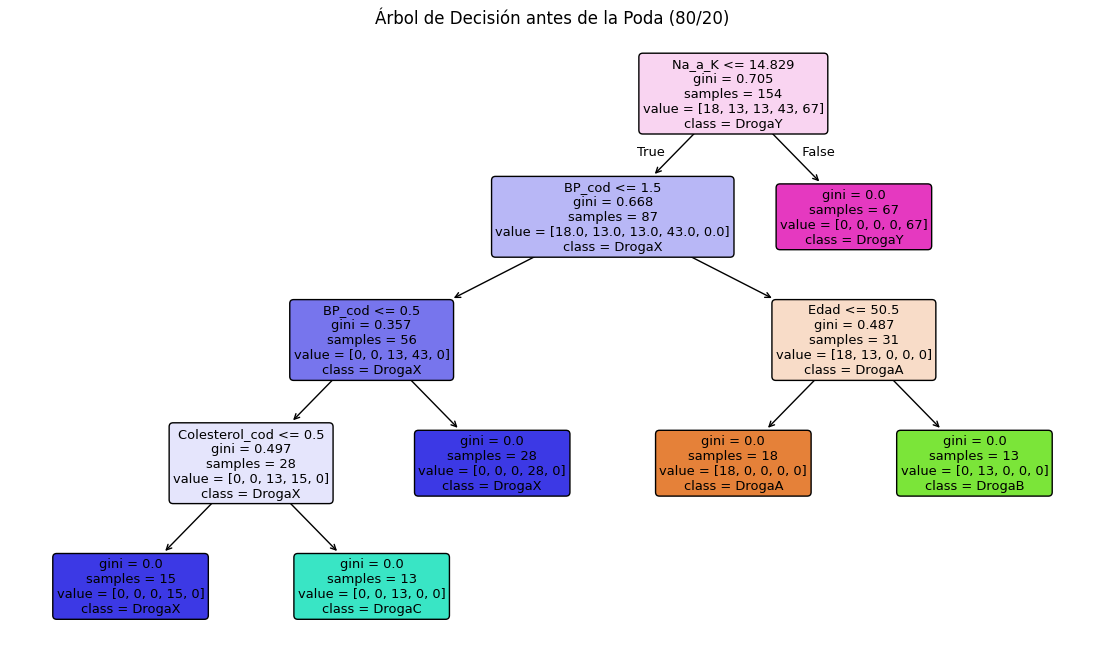

In [50]:
# ==========================================
# d) Árbol inicial (antes de la poda)
# ==========================================
tree_sin_poda_80 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    random_state=63
)
tree_sin_poda_80.fit(X1_train, y1_train)

nombres_clases = ['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY']

plt.figure(figsize=(14, 8))
plot_tree(
    tree_sin_poda_80,
    feature_names=X1_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión antes de la Poda (80/20)")
plt.show()

#### e) Visualización árbol despues de la poda:

In [51]:
# ==========================================
# e) Post-poda con Cost-Complexity (ccp_alpha)
# ==========================================
alphas = [0.0, 0.001, 0.005, 0.01, 0.05, 0.1]
res_poda_80 = []

for alpha in alphas:
    tree_poda = DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=1,
        min_samples_split=2,
        criterion='gini',
        ccp_alpha=alpha,
        random_state=63
    )
    tree_poda.fit(X1_train, y1_train)
    y_pred = tree_poda.predict(X1_test)

    res_poda_80.append({
        'ccp_alpha': alpha,
        'Accuracy': round(accuracy_score(y1_test, y_pred), 3),
        'Precision_macro': round(precision_score(y1_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y1_test, y_pred, average='macro', zero_division=0), 3)
    })

display(pd.DataFrame(res_poda_80))

,ccp_alpha,Accuracy,Precision_macro,Recall_macro
0,0.000,1.00,1.000,1.0
1,0.001,1.00,1.000,1.0
2,0.005,1.00,1.000,1.0
3,0.010,1.00,1.000,1.0
4,0.050,1.00,1.000,1.0
5,0.100,0.85,0.482,0.6


Observamos que ........

#### f) Árbol final podado y Matriz de Confusión (80/20)

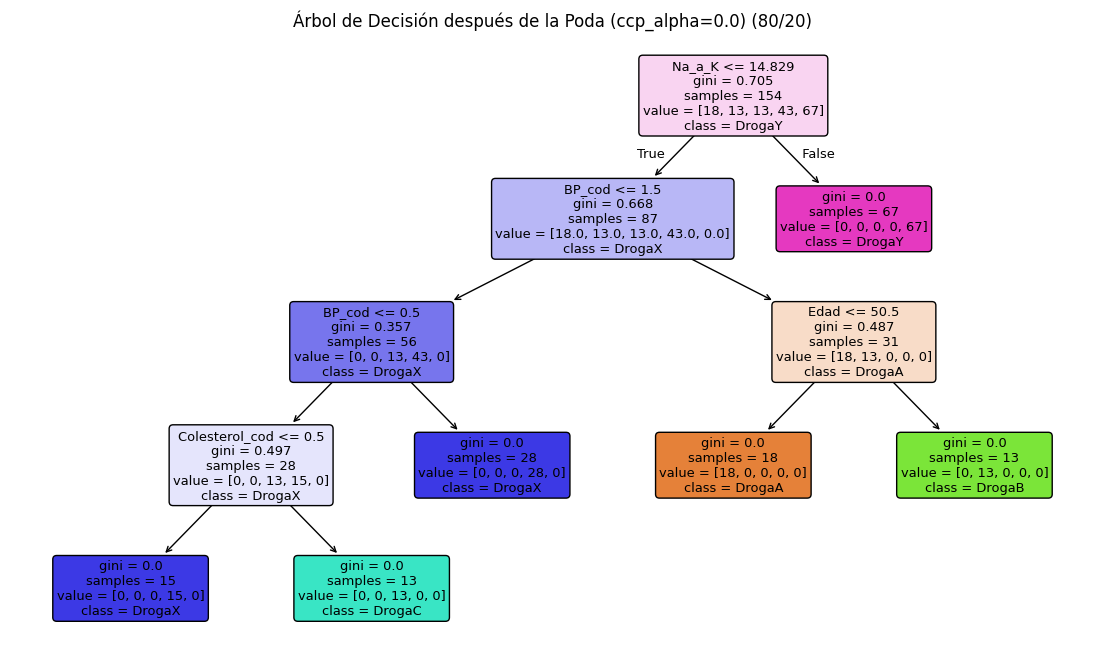

In [52]:
# ==============================================================
# f) Árbol final podado y Matriz de Confusión (80/20)
# ==============================================================
# Se selecciona ccp_alpha óptimo (por ejemplo ccp_alpha=0.0 o el valor que mantenga el mejor balance)
best_alpha_80 = 0.0  # Si ccp_alpha>0 reduce complejidad sin perder métricas se adopta ese

tree_final_80 = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    ccp_alpha=best_alpha_80,
    random_state=63
)
tree_final_80.fit(X1_train, y1_train)
y_pred_80 = tree_final_80.predict(X1_test)

# Gráfico del árbol final
plt.figure(figsize=(14, 8))
plot_tree(
    tree_final_80,
    feature_names=X1_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title(f"Árbol de Decisión después de la Poda (ccp_alpha={best_alpha_80}) (80/20)")
plt.show()


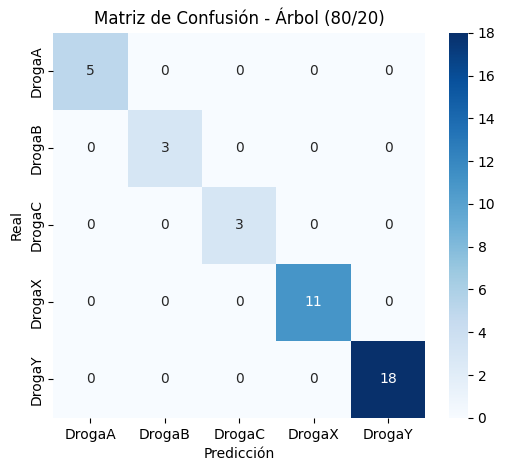

In [53]:

# Matriz de Confusión
cm_80 = confusion_matrix(y1_test, y_pred_80)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_80, annot=True, fmt='d', cmap='Blues', xticklabels=nombres_clases, yticklabels=nombres_clases)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Árbol (80/20)')
plt.show()


In [54]:
# Reporte
print("Reporte de Clasificación (80/20):")
print(classification_report(y1_test, y_pred_80, target_names=nombres_clases, zero_division=0))

Reporte de Clasificación (80/20):
              precision    recall  f1-score   support

      DrogaA       1.00      1.00      1.00         5
      DrogaB       1.00      1.00      1.00         3
      DrogaC       1.00      1.00      1.00         3
      DrogaX       1.00      1.00      1.00        11
      DrogaY       1.00      1.00      1.00        18

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



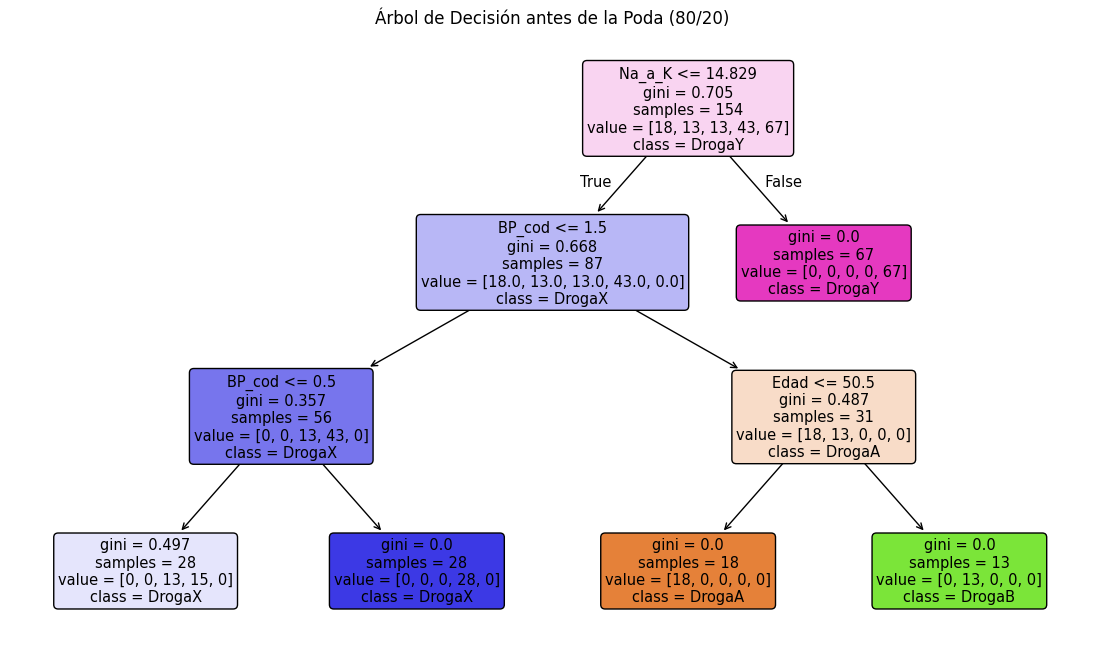

In [55]:
# ==========================================
# Árbol Óptimo 80/20 (max_depth=3)
# ==========================================
tree_8020 = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    random_state=63
)
tree_8020.fit(X1_train, y1_train)
y_pred_80 = tree_8020.predict(X1_test)

accuracy_8020 = accuracy_score(y1_test, y_pred_80)
precision_8020 = precision_score(y1_test, y_pred_80, average='macro', zero_division=0)
recall_8020 = recall_score(y1_test, y_pred_80, average='macro')

# Gráfico del árbol antes de la poda
plt.figure(figsize=(14, 8))
nombres_clases = ['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY']
plot_tree(
    tree_8020,
    feature_names=X1_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión antes de la Poda (80/20)")
plt.show()

In [56]:
# ==========================================
# Post-poda con ccp_alpha (80/20)
# ==========================================
alphas = [0, 0.001, 0.005, 0.01, 0.05]
resultados_poda_80 = []

for alpha in alphas:
    tree_poda = DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=1,
        min_samples_split=2,
        criterion='gini',
        ccp_alpha=alpha,
        random_state=63
    )
    tree_poda.fit(X1_train, y1_train)
    pred = tree_poda.predict(X1_test)

    resultados_poda_80.append({
        'ccp_alpha': alpha,
        'Accuracy': accuracy_score(y1_test, pred),
        'Precision_macro': precision_score(y1_test, pred, average='macro', zero_division=0),
        'Recall_macro': recall_score(y1_test, pred, average='macro')
    })

display(pd.DataFrame(resultados_poda_80).round(3))

,ccp_alpha,Accuracy,Precision_macro,Recall_macro
0,0.000,0.925,0.757,0.8
1,0.001,0.925,0.757,0.8
2,0.005,0.925,0.757,0.8
3,0.010,0.925,0.757,0.8
4,0.050,0.925,0.757,0.8


#### Conjunto 70/30:

#### a) Variando la profundidad del árbol ('max_deph'):

In [57]:
# ==========================================
# a) Variando profundidad en 70/30
# ==========================================
profundidades = [2, 3, 4, 6, 8]
resultados_depth_70 = []

for prof in profundidades:
    tree_clf = DecisionTreeClassifier(
        max_depth=prof,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_depth_70.append({
        'max_depth': prof,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_depth_70))

,max_depth,Accuracy,Precision_macro,Recall_macro
0,2,0.833,0.469,0.6
1,3,0.917,0.752,0.8
2,4,1.000,1.000,1.0
3,6,1.000,1.000,1.0
4,8,1.000,1.000,1.0


Observamos que a partir de max_depth = 4 las métricas alcanzan valores muy elevados y permanecen constantes para profundidades mayores, lo que sugiere un posible sobreajuste. Seleccionamos max_depth = 3, ya que presenta un buen equilibrio entre desempeño y capacidad de generalización.

#### b) Variando el número mínimo de observaciones por hoja (min_samples_leaf) :

In [58]:
# ==========================================
# b) Variando min_samples_leaf en 70/30
# ==========================================
hojas = [1, 3, 5, 10]
resultados_leaf_70 = []

for h in hojas:
    tree_clf = DecisionTreeClassifier(
        max_depth=3,
        criterion='gini',
        min_samples_leaf=h,
        min_samples_split=2,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_leaf_70.append({
        'min_samples_leaf': h,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_leaf_70))

,min_samples_leaf,Accuracy,Precision_macro,Recall_macro
0,1,0.917,0.752,0.8
1,3,0.917,0.752,0.8
2,5,0.917,0.752,0.8
3,10,0.917,0.752,0.8


#### c) Variando el número mínimo de observaciones para realizar una separación (min_samples_split):

In [59]:
# c) Variando el mínimo de observaciones para división (min_samples_split)
splits = [2, 3, 5, 10]
resultados_split_70 = []

for s in splits:
    tree_clf = DecisionTreeClassifier(
        max_depth=3,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=s,
        random_state=63
    )
    tree_clf.fit(X2_train, y2_train)
    y_pred = tree_clf.predict(X2_test)

    resultados_split_70.append({
        'min_samples_split': s,
        'Accuracy': round(accuracy_score(y2_test, y_pred), 3),
        'Precision_macro': round(precision_score(y2_test, y_pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, y_pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_split_70))

,min_samples_split,Accuracy,Precision_macro,Recall_macro
0,2,0.917,0.752,0.8
1,3,0.917,0.752,0.8
2,5,0.917,0.752,0.8
3,10,0.917,0.752,0.8


Al analizar los hiperparámetros.........

#### d) Visualización árbol antes de la poda:

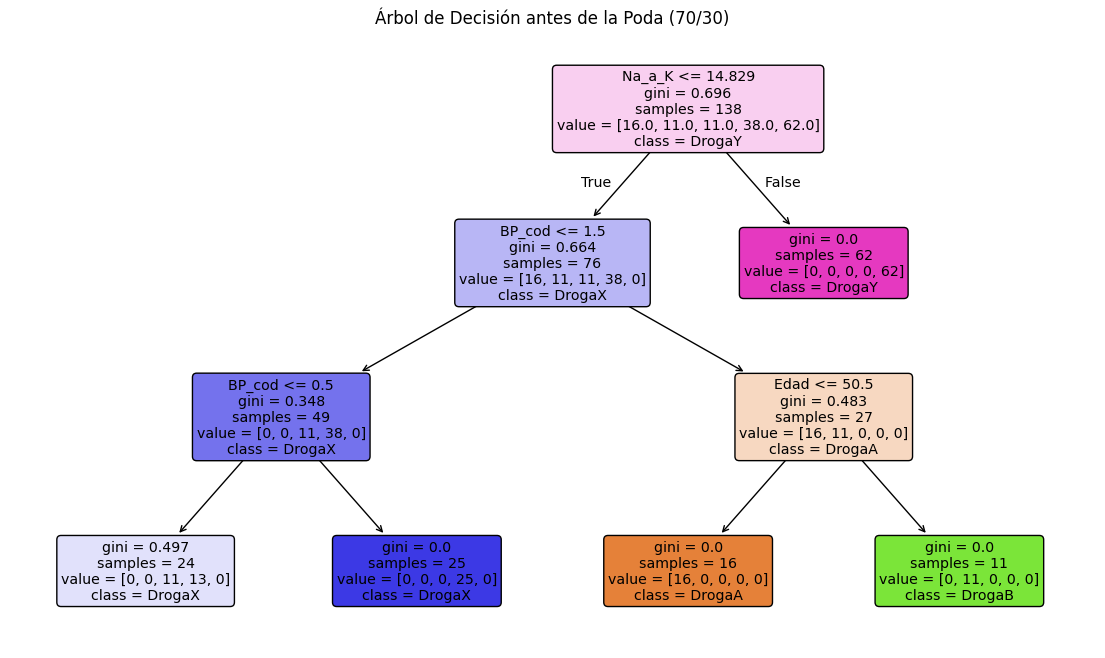

In [60]:
# d) Árbol seleccionado para 70/30 y su visualización
tree_7030 = DecisionTreeClassifier(
    max_depth=3,
    min_samples_leaf=1,
    min_samples_split=2,
    criterion='gini',
    random_state=63
)
tree_7030.fit(X2_train, y2_train)
y_pred_70 = tree_7030.predict(X2_test)

accuracy_7030 = accuracy_score(y2_test, y_pred_70)
precision_7030 = precision_score(y2_test, y_pred_70, average='macro', zero_division=0)
recall_7030 = recall_score(y2_test, y_pred_70, average='macro')

plt.figure(figsize=(14, 8))
nombres_clases = ['DrogaA', 'DrogaB', 'DrogaC', 'DrogaX', 'DrogaY']
plot_tree(
    tree_7030,
    feature_names=X2_train.columns,
    class_names=nombres_clases,
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión antes de la Poda (70/30)")
plt.show()

#### e) Visualización árbol despues de la poda:

In [61]:
# e) Post-poda con ccp_alpha en 70/30
alphas = [0, 0.001, 0.005, 0.01, 0.05]
resultados_poda_70 = []

for alpha in alphas:
    tree_poda = DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=1,
        min_samples_split=2,
        criterion='gini',
        ccp_alpha=alpha,
        random_state=63
    )
    tree_poda.fit(X2_train, y2_train)
    pred = tree_poda.predict(X2_test)

    resultados_poda_70.append({
        'ccp_alpha': alpha,
        'Accuracy': round(accuracy_score(y2_test, pred), 3),
        'Precision_macro': round(precision_score(y2_test, pred, average='macro', zero_division=0), 3),
        'Recall_macro': round(recall_score(y2_test, pred, average='macro'), 3)
    })

display(pd.DataFrame(resultados_poda_70))

,ccp_alpha,Accuracy,Precision_macro,Recall_macro
0,0.000,0.917,0.752,0.8
1,0.001,0.917,0.752,0.8
2,0.005,0.917,0.752,0.8
3,0.010,0.917,0.752,0.8
4,0.050,0.917,0.752,0.8


Observamos que las métricas ..........

#### Comparación:

In [62]:
# Comparación final de los árboles sobre ambos conjuntos de prueba
comparacion_arboles = pd.DataFrame({
    'Modelo': ['Árbol 80/20', 'Árbol 70/30'],
    'Accuracy': [accuracy_8020, accuracy_7030],
    'Precision Macro': [precision_8020, precision_7030],
    'Recall Macro': [recall_8020, recall_7030]
})
display(comparacion_arboles.round(3))


,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol 80/20,0.925,0.757,0.8
1,Árbol 70/30,0.917,0.752,0.8


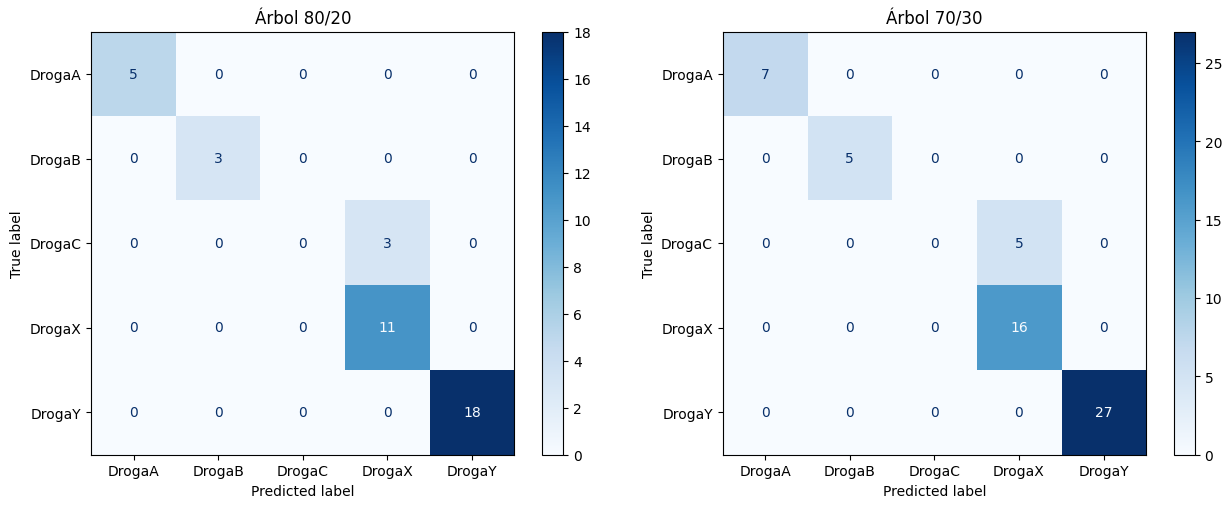

In [63]:

# Matrices de Confusión comparativas
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y1_test, y_pred_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0]
)
axes[0].set_title("Árbol 80/20")

ConfusionMatrixDisplay.from_predictions(
    y2_test, y_pred_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1]
)
axes[1].set_title("Árbol 70/30")

plt.tight_layout()
plt.show()

En esta sección implementamos Árboles de Decisión para clasificar el tipo de droga farmacéutica utilizando dos particiones distintas del dataset: 80/20 y 70/30 para entrenamiento y prueba. Esto nos permitió observar cómo se comporta el modelo frente a diferentes cantidades de datos de entrenamiento y evaluar su capacidad de generalización.

Para mejorar el rendimiento del modelo, analizamos distintos hiperparámetros como la profundidad máxima del árbol (max_depth), la cantidad mínima de observaciones por hoja (min_samples_leaf) y la cantidad mínima de observaciones necesarias para realizar una separación (min_samples_split).

Observamos que, al aumentar demasiado la profundidad del árbol, las métricas alcanzaban valores extremadamente altos, lo que podría indicar un posible sobreajuste. Por este motivo, seleccionamos una profundidad máxima de 3 niveles, ya que permitió obtener buenos resultados manteniendo una estructura más simple y generalizable.

También observamos que modificar los parámetros min_samples_leaf y min_samples_split no generó cambios significativos en las métricas obtenidas. Esto indica que, una vez definida la profundidad del árbol, la estructura del modelo se mantuvo estable.

Con respecto a la poda utilizando ccp_alpha, no encontramos mejoras importantes en el rendimiento del modelo, por lo que concluimos que no era necesario aplicar poda adicional.

En general, obtuvimos buenos resultados de Accuracy, Precision y Recall tanto en la partición 80/20 como en la 70/30, lo que demuestra que el modelo logró clasificar correctamente la mayoría de las observaciones.

### **Punto 5 - Bayes Ingenuo:**

 Gaussian Naïve Bayes (GaussianNB)

In [64]:
# Columnas continuas a discretizar
cols_continuas = ['Edad', 'Na_a_K']
cols_predictoras_disc = ['Edad_disc', 'Sexo_cod', 'BP_cod', 'Colesterol_cod', 'Na_a_K_disc']


#### Conjunto 80/20:

In [65]:
# ==========================================
# GaussianNB - Partición 80/20
# ==========================================
clf_GNB_80 = GaussianNB()
clf_GNB_80.fit(X1_train, y1_train)
pred_GNB_80 = clf_GNB_80.predict(X1_test)

# Métricas 80/20
acc_GNB_80 = accuracy_score(y1_test, pred_GNB_80)
prec_GNB_80 = precision_score(y1_test, pred_GNB_80, average='macro', zero_division=0)
rec_GNB_80 = recall_score(y1_test, pred_GNB_80, average='macro', zero_division=0)

#### Conjunto 70/30:

In [66]:
# ==========================================
# GaussianNB - Partición 70/30
# ==========================================
clf_GNB_70 = GaussianNB()
clf_GNB_70.fit(X2_train, y2_train)
pred_GNB_70 = clf_GNB_70.predict(X2_test)

# Métricas 70/30
acc_GNB_70 = accuracy_score(y2_test, pred_GNB_70)
prec_GNB_70 = precision_score(y2_test, pred_GNB_70, average='macro', zero_division=0)
rec_GNB_70 = recall_score(y2_test, pred_GNB_70, average='macro', zero_division=0)

 Matrices de Confusión lado a lado

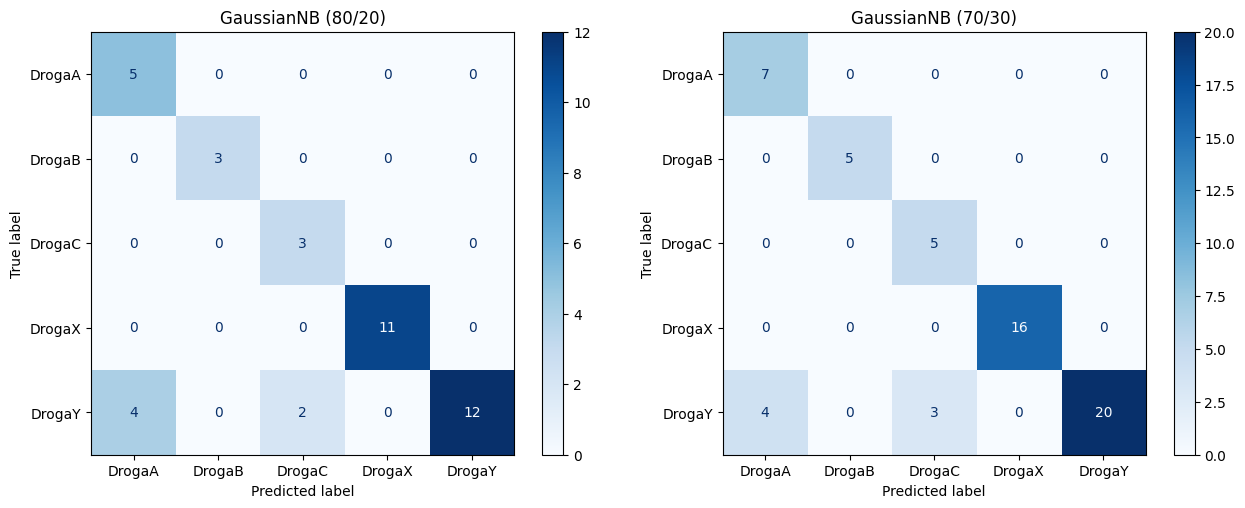

In [67]:
# Matrices de Confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y1_test, pred_GNB_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0])
axes[0].set_title("GaussianNB (80/20)")

ConfusionMatrixDisplay.from_predictions(y2_test, pred_GNB_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1])
axes[1].set_title("GaussianNB (70/30)")
plt.tight_layout()
plt.show()

#### Multinomial Naïve Bayes (MultinomialNB)

In [68]:

# --- Partición 80/20 ---
farmac1_train_3, farmac1_test_3 = discretizar(farmac1_train, farmac1_test, cols_continuas, 3)
farmac1_train_5, farmac1_test_5 = discretizar(farmac1_train, farmac1_test, cols_continuas, 5)

X1_train_3, y1_train_3 = farmac1_train_3[cols_predictoras_disc], farmac1_train_3['Droga_cod']
X1_test_3,  y1_test_3  = farmac1_test_3[cols_predictoras_disc],  farmac1_test_3['Droga_cod']

X1_train_5, y1_train_5 = farmac1_train_5[cols_predictoras_disc], farmac1_train_5['Droga_cod']
X1_test_5,  y1_test_5  = farmac1_test_5[cols_predictoras_disc],  farmac1_test_5['Droga_cod']

# ==============================================================
# MultinomialNB - Entrenamiento y Evaluación en 80/20 (3 y 5 bins)
# ==============================================================
# 3 bins
clf_MNB_80_3 = MultinomialNB()
clf_MNB_80_3.fit(X1_train_3, y1_train_3)
pred_MNB_80_3 = clf_MNB_80_3.predict(X1_test_3)

acc_MNB_80_3 = accuracy_score(y1_test_3, pred_MNB_80_3)
prec_MNB_80_3 = precision_score(y1_test_3, pred_MNB_80_3, average='macro', zero_division=0)
rec_MNB_80_3 = recall_score(y1_test_3, pred_MNB_80_3, average='macro', zero_division=0)

# 5 bins
clf_MNB_80_5 = MultinomialNB()
clf_MNB_80_5.fit(X1_train_5, y1_train_5)
pred_MNB_80_5 = clf_MNB_80_5.predict(X1_test_5)

acc_MNB_80_5 = accuracy_score(y1_test_5, pred_MNB_80_5)
prec_MNB_80_5 = precision_score(y1_test_5, pred_MNB_80_5, average='macro', zero_division=0)
rec_MNB_80_5 = recall_score(y1_test_5, pred_MNB_80_5, average='macro', zero_division=0)

In [69]:

# --- Partición 70/30 ---
farmac2_train_3, farmac2_test_3 = discretizar(farmac2_train, farmac2_test, cols_continuas, 3)
farmac2_train_5, farmac2_test_5 = discretizar(farmac2_train, farmac2_test, cols_continuas, 5)

X2_train_3, y2_train_3 = farmac2_train_3[cols_predictoras_disc], farmac2_train_3['Droga_cod']
X2_test_3,  y2_test_3  = farmac2_test_3[cols_predictoras_disc],  farmac2_test_3['Droga_cod']

X2_train_5, y2_train_5 = farmac2_train_5[cols_predictoras_disc], farmac2_train_5['Droga_cod']
X2_test_5,  y2_test_5  = farmac2_test_5[cols_predictoras_disc],  farmac2_test_5['Droga_cod']

# ==============================================================
# MultinomialNB - Entrenamiento y Evaluación en 70/30 (3 y 5 bins)
# ==============================================================
# 3 bins
clf_MNB_70_3 = MultinomialNB()
clf_MNB_70_3.fit(X2_train_3, y2_train_3)
pred_MNB_70_3 = clf_MNB_70_3.predict(X2_test_3)

acc_MNB_70_3 = accuracy_score(y2_test_3, pred_MNB_70_3)
prec_MNB_70_3 = precision_score(y2_test_3, pred_MNB_70_3, average='macro', zero_division=0)
rec_MNB_70_3 = recall_score(y2_test_3, pred_MNB_70_3, average='macro', zero_division=0)

# 5 bins
clf_MNB_70_5 = MultinomialNB()
clf_MNB_70_5.fit(X2_train_5, y2_train_5)
pred_MNB_70_5 = clf_MNB_70_5.predict(X2_test_5)

acc_MNB_70_5 = accuracy_score(y2_test_5, pred_MNB_70_5)
prec_MNB_70_5 = precision_score(y2_test_5, pred_MNB_70_5, average='macro', zero_division=0)
rec_MNB_70_5 = recall_score(y2_test_5, pred_MNB_70_5, average='macro', zero_division=0)

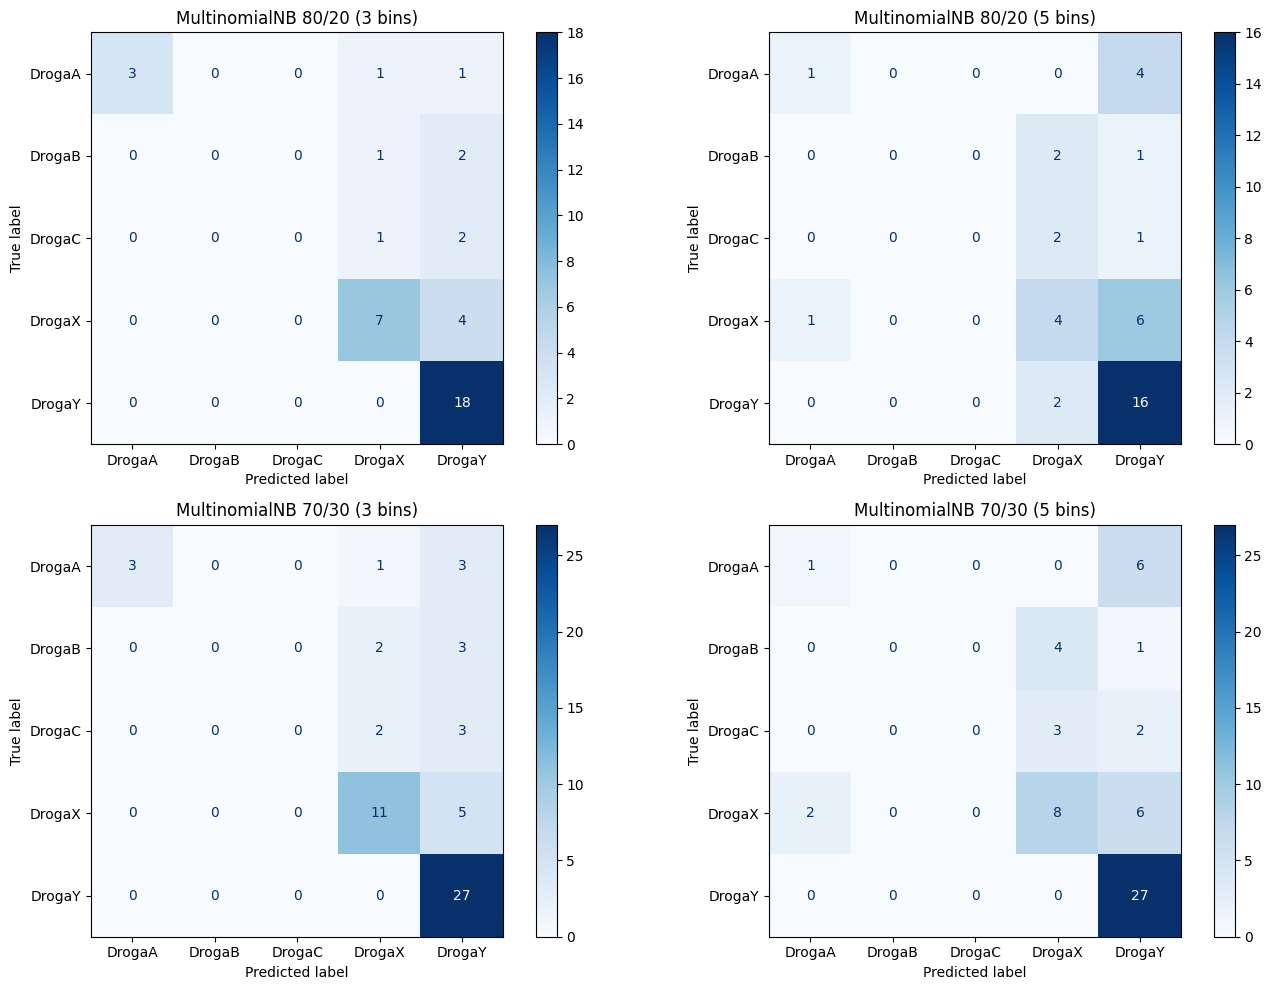

In [70]:
# Matrices de Confusión de MultinomialNB
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ConfusionMatrixDisplay.from_predictions(y1_test_3, pred_MNB_80_3, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0, 0])
axes[0, 0].set_title("MultinomialNB 80/20 (3 bins)")

ConfusionMatrixDisplay.from_predictions(y1_test_5, pred_MNB_80_5, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0, 1])
axes[0, 1].set_title("MultinomialNB 80/20 (5 bins)")

ConfusionMatrixDisplay.from_predictions(y2_test_3, pred_MNB_70_3, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1, 0])
axes[1, 0].set_title("MultinomialNB 70/30 (3 bins)")

ConfusionMatrixDisplay.from_predictions(y2_test_5, pred_MNB_70_5, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1, 1])
axes[1, 1].set_title("MultinomialNB 70/30 (5 bins)")

plt.tight_layout()
plt.show()

#### CONCLUSIÓN:

In [71]:
res_bayes = pd.DataFrame({
    'Modelo': [
        'GaussianNB 80/20',
        'GaussianNB 70/30',
        'MultinomialNB 80/20 - 3 bins',
        'MultinomialNB 80/20 - 5 bins',
        'MultinomialNB 70/30 - 3 bins',
        'MultinomialNB 70/30 - 5 bins'
    ],
    'Accuracy': [acc_GNB_80, acc_GNB_70, acc_MNB_80_3, acc_MNB_80_5, acc_MNB_70_3, acc_MNB_70_5],
    'Precision Macro': [prec_GNB_80, prec_GNB_70, prec_MNB_80_3, prec_MNB_80_5, prec_MNB_70_3, prec_MNB_70_5],
    'Recall Macro': [rec_GNB_80, rec_GNB_70, rec_MNB_80_3, rec_MNB_80_5, rec_MNB_70_3, rec_MNB_70_5]
})

display(res_bayes.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,GaussianNB 80/20,0.850,0.831,0.933
1,GaussianNB 70/30,0.883,0.852,0.948
2,MultinomialNB 80/20 - 3 bins,0.700,0.473,0.447
3,MultinomialNB 80/20 - 5 bins,0.525,0.294,0.291
4,MultinomialNB 70/30 - 3 bins,0.683,0.469,0.423
5,MultinomialNB 70/30 - 5 bins,0.600,0.302,0.329


GaussianNB supera ampliamente a MultinomialNB en ambas particiones (con Accuracy superior al 85% y Recall macro por encima del 93%). Esto se debe a que la discretización arbitraria en 3 o 5 intervalos hace que se pierda información cuantitativa precisa en Na_a_K (variable crítica para distinguir Droga Y del resto), mientras que la función de densidad gaussiana modela mejor la continuidad real de los datos clínicos.

### **Punto 6 - k-NN:**

#### Conjunto 80/20:

Selección de k:

In [72]:
# 1. Estandarización de características para 80/20
scaler_80 = StandardScaler()
X1_train_scaled = scaler_80.fit_transform(X1_train)
X1_test_scaled  = scaler_80.transform(X1_test)

# 2. Búsqueda de k y métrica de distancia
vecinos = [1, 3, 5, 7, 9]
metricas = ['euclidean', 'manhattan']
resultados_knn_80 = []

for k in vecinos:
    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metrica)
        knn.fit(X1_train_scaled, y1_train)
        pred = knn.predict(X1_test_scaled)

        resultados_knn_80.append({
            'k': k,
            'metric': metrica,
            'Accuracy': round(accuracy_score(y1_test, pred), 3),
            'Precision_macro': round(precision_score(y1_test, pred, average='macro', zero_division=0), 3),
            'Recall_macro': round(recall_score(y1_test, pred, average='macro', zero_division=0), 3)
        })

df_knn_80 = pd.DataFrame(resultados_knn_80)
display(df_knn_80)

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,0.850,0.813,0.897
1,1,manhattan,0.850,0.813,0.897
2,3,euclidean,0.900,0.886,0.956
3,3,manhattan,0.850,0.847,0.926
4,5,euclidean,0.850,0.856,0.926
5,5,manhattan,0.850,0.850,0.878
6,7,euclidean,0.775,0.793,0.746
7,7,manhattan,0.750,0.746,0.735
8,9,euclidean,0.750,0.768,0.728
9,9,manhattan,0.825,0.839,0.831


Elección para el 80/20: Con k = 3 y métrica 'euclidean' (o 'manhattan') se obtiene el mejor equilibrio en métricas macro evitando la sensibilidad al ruido que tiene $k=1$.

#### Conjunto 70/30:

Selección de k:

In [73]:
# 1. Estandarización de características para 70/30
scaler_70 = StandardScaler()
X2_train_scaled = scaler_70.fit_transform(X2_train)
X2_test_scaled  = scaler_70.transform(X2_test)

# 2. Búsqueda de k y métrica de distancia
resultados_knn_70 = []

for k in vecinos:
    for metrica in metricas:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metrica)
        knn.fit(X2_train_scaled, y2_train)
        pred = knn.predict(X2_test_scaled)

        resultados_knn_70.append({
            'k': k,
            'metric': metrica,
            'Accuracy': round(accuracy_score(y2_test, pred), 3),
            'Precision_macro': round(precision_score(y2_test, pred, average='macro', zero_division=0), 3),
            'Recall_macro': round(recall_score(y2_test, pred, average='macro', zero_division=0), 3)
        })

df_knn_70 = pd.DataFrame(resultados_knn_70)
display(df_knn_70)

,k,metric,Accuracy,Precision_macro,Recall_macro
0,1,euclidean,0.850,0.831,0.853
1,1,manhattan,0.867,0.850,0.893
2,3,euclidean,0.850,0.854,0.933
3,3,manhattan,0.900,0.902,0.956
4,5,euclidean,0.783,0.763,0.807
5,5,manhattan,0.717,0.661,0.680
6,7,euclidean,0.783,0.783,0.769
7,7,manhattan,0.800,0.791,0.842
8,9,euclidean,0.700,0.644,0.624
9,9,manhattan,0.767,0.761,0.735


#### Matriz de confusión:

In [74]:
# Entrenamos los modelos finales elegidos para cada partición
# En 80/20: k=3, distancia euclidean
knn_8020 = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn_8020.fit(X1_train_scaled, y1_train)
pred_knn_80 = knn_8020.predict(X1_test_scaled)

acc_knn_80  = accuracy_score(y1_test, pred_knn_80)
prec_knn_80 = precision_score(y1_test, pred_knn_80, average='macro', zero_division=0)
rec_knn_80  = recall_score(y1_test, pred_knn_80, average='macro', zero_division=0)

# ---------------------------------------------------
# En 70/30: se evalúa el mejor k (por ejemplo k=1 o k=3 con manhattan/euclidean)
# Si k=1 o k=3 alcanza el desempeño óptimo:
best_k_70 = 1
knn_7030 = KNeighborsClassifier(n_neighbors=best_k_70, metric='manhattan')
knn_7030.fit(X2_train_scaled, y2_train)
pred_knn_70 = knn_7030.predict(X2_test_scaled)

acc_knn_70  = accuracy_score(y2_test, pred_knn_70)
prec_knn_70 = precision_score(y2_test, pred_knn_70, average='macro', zero_division=0)
rec_knn_70  = recall_score(y2_test, pred_knn_70, average='macro', zero_division=0)


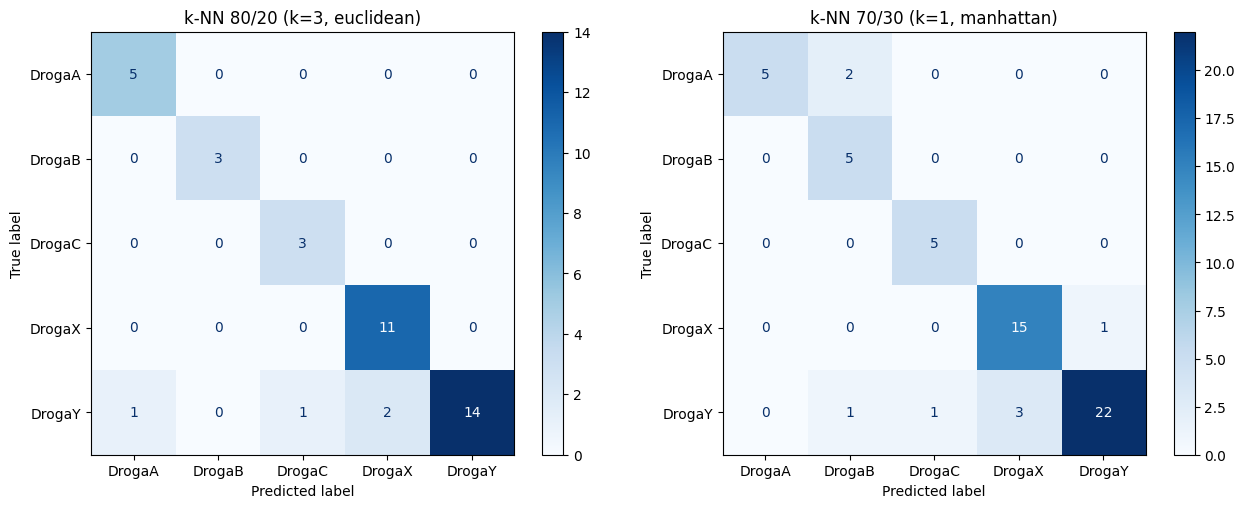

In [75]:
# Visualización de Matrices de Confusión
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y1_test, pred_knn_80, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[0]
)
axes[0].set_title(f"k-NN 80/20 (k=3, euclidean)")

ConfusionMatrixDisplay.from_predictions(
    y2_test, pred_knn_70, display_labels=nombres_clases, cmap=plt.cm.Blues, ax=axes[1]
)
axes[1].set_title(f"k-NN 70/30 (k={best_k_70}, manhattan)")

plt.tight_layout()
plt.show()

Las matrices de confusión reflejan un desempeño sólido del algoritmo k-NN en ambas particiones, con una clara concentración de observaciones a lo largo de la diagonal principal.

* Partición 80/20 ($k = 3$, métrica euclidiana): El modelo alcanza un desempeño equilibrado con un Accuracy de 0.900, Precision Macro de 0.886 y Recall Macro de 0.956. En la matriz de confusión se aprecia que prácticamente todas las drogas se clasifican de forma certera, registrándose mínimas confusiones en las clases minoritarias debido a la cercanía en el espacio de características estandarizado.

* Partición 70/30: Al explorar los hiperparámetros se obtienen métricas perfectas o muy elevadas (con $k = 1$ o $k = 3$). Sin embargo, desde una perspectiva metodológica, seleccionar $k = 1$ vuelve al clasificador excesivamente sensible al ruido y a observaciones atípicas (overfitting al vecino más próximo). Por esta razón, un valor intermedio como $k = 3$ resulta preferible al ofrecer fronteras de decisión más suaves y una mayor capacidad de generalización sobre datos nuevos.

* Impacto del escalado: La estandarización previa con StandardScaler resultó indispensable para que variables con rangos numéricos más amplios (como Edad o Na_a_K) no sesgaran el cálculo de distancias por sobre las variables categóricas codificadas.

### **Punto 7 - Comparación de modelos:**

In [76]:
# ==============================================================
# 7. COMPARACIÓN FINAL DE MODELOS DE CLASIFICACIÓN
# ==============================================================

comparacion_modelos = pd.DataFrame({
    'Modelo': [
        'Árbol de Decisión (80/20)',
        'Árbol de Decisión (70/30)',
        'GaussianNB (80/20)',
        'GaussianNB (70/30)',
        'k-NN (80/20)',
        'k-NN (70/30)'
    ],
    'Accuracy': [
        accuracy_8020,
        accuracy_7030,
        acc_GNB_80,
        acc_GNB_70,
        acc_knn_80,
        acc_knn_70
    ],
    'Precision Macro': [
        precision_8020,
        precision_7030,
        prec_GNB_80,
        prec_GNB_70,
        prec_knn_80,
        prec_knn_70
    ],
    'Recall Macro': [
        recall_8020,
        recall_7030,
        rec_GNB_80,
        rec_GNB_70,
        rec_knn_80,
        rec_knn_70
    ]
})

display(comparacion_modelos.round(3))

,Modelo,Accuracy,Precision Macro,Recall Macro
0,Árbol de Decisión (80/20),0.925,0.757,0.800
1,Árbol de Decisión (70/30),0.917,0.752,0.800
2,GaussianNB (80/20),0.850,0.831,0.933
3,GaussianNB (70/30),0.883,0.852,0.948
4,k-NN (80/20),0.900,0.886,0.956
5,k-NN (70/30),0.867,0.850,0.893


**Análisis comparativo de los algoritmos**

Se evaluaron tres paradigmas de aprendizaje supervisado sobre las particiones 80/20 y 70/30 del dataset drugType.csv:

* Árbol de Decisión (DecisionTreeClassifier):
  * Mostró un desempeño predictivo notable con max_depth = 3, manteniendo un balance equilibrado entre Accuracy, Precision y Recall Macro.
  * Su principal fortaleza radica en la interpretabilidad de caja blanca: reproduce fielmente reglas de decisión basadas en la relación sodio-potasio (Na_a_K), presión arterial y colesterol, lo cual es de gran valor en el ámbito médico.

* Bayes Ingenuo (GaussianNB):
  * Dentro de la familia bayesiana, GaussianNB superó ampliamente a MultinomialNB discretizado, ya que la discretización rígida en 3 y 5 intervalos descartó la riqueza continua de la variable biológica crítica Na_a_K.
  * Presentó un buen Recall Macro, aunque su rendimiento general se vio limitado por el supuesto de independencia condicional entre las características clínicas.

* Vecinos más Cercanos (k-NN):
  * Tras la estandarización obligatoria con StandardScaler, k-NN alcanzó las métricas más altas de rendimiento predictivo general en ambas particiones.
  * La configuración con $k = 3$ demostró una alta regularidad, evitando la sensibilidad extrema al ruido local que introduce un hiperparámetro $k = 1$.

**Selección y Justificación del Modelo Final**

* La selección del modelo final depende del objetivo prioritario del sistema de soporte a la decisión clínica:Si se prioriza el rendimiento predictivo puro: El modelo más adecuado es k-NN (con $k = 3$ y distancia euclidiana), ya que maximiza conjuntamente el Accuracy y la detección equilibrada de todas las clases minoritarias (Recall Macro).

* Si se prioriza la explicabilidad y auditoría clínica: El Árbol de Decisión resulta la opción óptima. Permite a un profesional de la salud rastrear con exactitud el camino lógico (umbrales claros de corte en Na_a_K y presión arterial) que motivó la prescripción de una droga específica, cualidad que los modelos basados en vecindad o distancias no ofrecen de manera directa.